In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/LICENSE.txt
/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/CC-BY-4.0.txt
/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates/IDRiD_30_EX.tif
/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates/IDRiD_17_EX.tif
/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard Exudates/IDRiD_44_EX.tif
/kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset/A.%20Segmentation/A. Segmentation/2. All Segmentation Groundtruths/a. Training Set/3. Hard

In [19]:
# ============ CELL 1 : IMPORT LIBRARIES ============
import os, sys, re, csv, json, time, shutil, random, warnings, subprocess
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

def _need(pkg, imp=None):
    try: __import__(imp or pkg)
    except ImportError: subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', pkg])
for _p in ('timm', 'kagglehub', 'openpyxl'): _need(_p)

import cv2
cv2.setNumThreads(0)                      # avoid thread deadlocks inside DataLoader workers
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T
import timm, kagglehub
from sklearn.metrics import (precision_score, recall_score, f1_score, roc_auc_score, roc_curve, auc,
                             multilabel_confusion_matrix, cohen_kappa_score, confusion_matrix)
from sklearn.model_selection import StratifiedGroupKFold
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print('torch', torch.__version__, '| timm', timm.__version__, '| cuda available:', torch.cuda.is_available())

torch 2.11.0+cu128 | timm 1.0.29 | cuda available: True


In [20]:
# ============ CELL 2 : PATHS + FIND THE 5 DATASETS (Kaggle: right panel -> Add Input) ============
IS_COLAB  = 'google.colab' in sys.modules
KAGGLE_INPUT, KAGGLE_WORK = Path('/kaggle/input'), Path('/kaggle/working')
IS_KAGGLE = KAGGLE_WORK.exists()
ROOT     = KAGGLE_WORK if IS_KAGGLE else (Path('/content') if IS_COLAB else Path('./work'))
DATA_DIR = ROOT / 'datasets'
OUT_DIR  = ROOT / 'outputs'                      # models, csv, figures, reports are saved here
for d in (DATA_DIR, OUT_DIR, OUT_DIR / 'figs', OUT_DIR / 'reports'): d.mkdir(parents=True, exist_ok=True)

# a dataset is recognised by a keyword in its Kaggle folder name (change the keyword if your upload has another name)
KEYWORDS = {
    'odir'  : ('odir', 'ocular-disease'),            # ODIR-5K        : 8 disease labels
    'aptos' : ('224x224', 'aptos'),                  # APTOS 2019     : DR grade 0-4
    'idrid' : ('indian-diabetic', 'idrid'),          # IDRiD          : Part B grade + Part A lesion masks
    'refuge': ('refuge',),                           # REFUGE         : glaucoma label + disc/cup masks
    'fgadr' : ('fgadr',),                            # FGADR (optional, needs authors' permission): lesion masks
    'ddr'   : ('ddr',),                              # DDR (optional): DR grade + 757 lesion-mask images
}
MANUAL_PATHS = {}      # if something is not found, write it here, e.g. {'fgadr': '/kaggle/input/my-fgadr-dataset'}

def sub_dirs(base, depth=3):
    out, stack = [], [(Path(base), 0)]
    while stack:
        p, d = stack.pop()
        try: kids = sorted(k for k in p.iterdir() if k.is_dir())
        except Exception: continue
        for k in kids:
            out.append(k)
            if d + 1 < depth: stack.append((k, d + 1))
    return sorted(out, key=lambda q: (len(q.parts), str(q)))        # shallowest folder first = dataset root

def related(a, b): return a == b or a in b.parents or b in a.parents

PATHS = {}
if IS_KAGGLE and KAGGLE_INPUT.exists():
    cands = sub_dirs(KAGGLE_INPUT, 3)
    for name, keys in KEYWORDS.items():
        hit = next((p for p in cands if any(k in p.name.lower() for k in keys)), None)
        if hit is not None: PATHS[name] = hit
    if 'fgadr' not in PATHS:                      # uploaded under another name -> look for lesion-mask folders in unused datasets
        used = list(PATHS.values())
        for top in [p for p in cands if len(p.relative_to(KAGGLE_INPUT).parts) <= 2 and not any(related(p, u) for u in used)]:
            try:
                if any('microaneurysm' in q.name.lower() for q in top.rglob('*') if q.is_dir()): PATHS['fgadr'] = top; break
            except Exception: pass
else:                                             # Colab / local: public datasets by kaggle API, FGADR from DATA_DIR/fgadr
    def slug(x):
        m = re.search(r'kaggle\.com/datasets/([^/\s?#]+/[^/\s?#]+)', x); return m.group(1) if m else x.strip().strip('/')
    SOURCES = {'odir'  : 'andrewmvd/ocular-disease-recognition-odir5k', 'aptos': 'sovitrath/diabetic-retinopathy-224x224-2019-data',
               'idrid' : 'aaryapatel98/indian-diabetic-retinopathy-image-dataset', 'refuge': 'victorlemosml/refuge2'}
    if IS_COLAB:
        try:
            from google.colab import userdata
            os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME'); os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
        except Exception: print('no Colab secrets -> kagglehub will ask for login')
    for name, ref in SOURCES.items():
        try: PATHS[name] = Path(kagglehub.dataset_download(slug(ref)))
        except Exception as e: print(f'[{name}] download failed: {str(e)[:150]}')
    if (DATA_DIR / 'fgadr').exists(): PATHS['fgadr'] = DATA_DIR / 'fgadr'
for k, v in MANUAL_PATHS.items(): PATHS[k] = Path(v)

_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')
for name in KEYWORDS:
    if name not in PATHS: print(f'[{name:6s}] NOT FOUND  -> add the dataset as Input, or set MANUAL_PATHS[{name!r}]'); continue
    n_img = sum(1 for p in PATHS[name].rglob('*') if p.suffix.lower() in _EXT)
    print(f'[{name:6s}] {PATHS[name]}  ({n_img} image files)')
    for p in sorted(PATHS[name].iterdir())[:8]: print('            ', p.name + ('/' if p.is_dir() else ''))
print('\nloaded datasets:', list(PATHS))
missing = [k for k in ('odir', 'aptos', 'idrid', 'refuge') if k not in PATHS]      # fgadr / ddr are optional
if missing: print('WARNING - core datasets missing:', missing)


[odir  ] /kaggle/input/datasets/andrewmvd/ocular-disease-recognition-odir5k  (14392 image files)
             ODIR-5K/
             full_df.csv
             preprocessed_images/
[aptos ] /kaggle/input/datasets/sovitrath/diabetic-retinopathy-224x224-gaussian-filtered  (3662 image files)
             gaussian_filtered_images/
             train.csv
[idrid ] /kaggle/input/datasets/aaryapatel98/indian-diabetic-retinopathy-image-dataset  (1476 image files)
             A.%20Segmentation/
             B.%20Disease%20Grading/
             C.%20Localization/
[refuge] /kaggle/input/datasets/victorlemosml/refuge2  (2400 image files)
             REFUGE2/
[fgadr ] NOT FOUND  -> add the dataset as Input, or set MANUAL_PATHS['fgadr']
[ddr   ] NOT FOUND  -> add the dataset as Input, or set MANUAL_PATHS['ddr']

loaded datasets: ['odir', 'aptos', 'idrid', 'refuge']


In [21]:
# ============ CELL 3 : DATALOADER (train 70% / test 20% / val 10%) ============
CLASSES = ['N', 'D', 'G', 'C', 'A', 'H', 'M', 'O']      # Normal, Diabetic ret., Glaucoma, Cataract, AMD, Hypertensive, Myopia, Other
CLS_IDX = {c: i for i, c in enumerate(CLASSES)}
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff')

def index_images(root):
    return [p for p in Path(root).rglob('*') if p.suffix.lower() in IMG_EXT]

def multi_hot(*names):
    v = {c: 0 for c in CLASSES}
    for n in names: v[n] = 1
    return v

# ---------- ODIR-5K : 8-class multi-label from diagnostic keywords ----------
def parse_keywords(kw):
    s = str(kw).lower()
    for ch in ('，', '；', ';', '、'): s = s.replace(ch, ',')
    lab = {c: 0 for c in CLASSES}; drop = False
    for t in [t.strip() for t in s.split(',') if t.strip() and t.strip() != 'nan']:
        if 'anterior segment' in t or 'no fundus' in t: drop = True; continue
        if any(q in t for q in ('low image quality', 'image offset', 'lens dust', 'photographically invisible')): continue
        if   'normal fundus' in t: lab['N'] = 1
        elif 'hypertensive' in t: lab['H'] = 1
        elif 'chorioretinopathy' in t or 'central serous' in t: lab['O'] = 1
        elif 'proliferative' in t or 'diabet' in t: lab['D'] = 1
        elif 'glaucoma' in t: lab['G'] = 1
        elif 'cataract' in t: lab['C'] = 1
        elif 'macular degeneration' in t: lab['A'] = 1
        elif 'myop' in t: lab['M'] = 1
        else: lab['O'] = 1
    if any(lab[c] for c in CLASSES[1:]): lab['N'] = 0
    return lab, drop

def load_odir(root):
    tab = [p for p in Path(root).rglob('*') if p.name.lower() == 'data.xlsx'] + [p for p in Path(root).rglob('*') if p.name.lower() == 'full_df.csv']
    t = tab[0]; df = pd.read_excel(t) if t.suffix.lower() == '.xlsx' else pd.read_csv(t)
    idx = {}
    for q in index_images(root):                       # prefer the original "Training Images" folder over "preprocessed_images"
        pref = 'training' in str(q).lower()
        if q.name not in idx or (pref and not idx[q.name][1]): idx[q.name] = (q, pref)
    rows = []
    for _, r in df.iterrows():
        for side in ('Left', 'Right'):
            fn = str(r[f'{side}-Fundus'])
            if fn not in idx: continue
            lab, drop = parse_keywords(r[f'{side}-Diagnostic Keywords'])
            if drop or sum(lab.values()) == 0: continue
            rows.append(dict(path=str(idx[fn][0]), pid=f'odir_{int(r["ID"])}', source='odir', **lab))   # both eyes share pid -> no leakage
    return pd.DataFrame(rows)

# ---------- APTOS / IDRiD : DR grade 0 -> Normal(N), grade >= 1 -> Diabetic retinopathy(D) ----------
def load_aptos(root):
    csvs = [p for p in Path(root).rglob('*.csv') if {'id_code', 'diagnosis'} <= set(pd.read_csv(p, nrows=1).columns)]
    lab = pd.read_csv(csvs[0]); stem = {p.stem: p for p in index_images(root)}
    rows = [dict(path=str(stem[r.id_code]), pid=f'aptos_{r.id_code}', source='aptos', grade=int(r.diagnosis), **multi_hot('D' if r.diagnosis >= 1 else 'N'))
            for r in lab.itertuples() if r.id_code in stem]
    return pd.DataFrame(rows)

def load_idrid(root):
    """IDRiD Part B (Disease Grading): 'Retinopathy grade' 0 -> N, >=1 -> D"""
    stem = {p.stem.lower(): p for p in index_images(root) if 'disease grading' in str(p).lower().replace('_', ' ') and 'original' in str(p).lower()}
    rows = []
    for c in Path(root).rglob('*.csv'):
        t = pd.read_csv(c); col = {x.strip().lower(): x for x in t.columns}
        if 'image name' in col and 'retinopathy grade' in col:
            for _, r in t.iterrows():
                nm = str(r[col['image name']]).strip().lower(); p = stem.get(nm)
                if p is not None: rows.append(dict(path=str(p), pid=f'idrid_{nm}', source='idrid', grade=int(r[col['retinopathy grade']]), **multi_hot('D' if int(r[col['retinopathy grade']]) >= 1 else 'N')))
    if not rows: raise RuntimeError('IDRiD Part B images/labels not found')
    return pd.DataFrame(rows)

# ---------- REFUGE : glaucoma (G) / non-glaucoma (N) from the file name (REFUGE naming: g0001 = glaucoma, n0001 = non-glaucoma) ----------
MASK_WORDS = ('mask', 'annot', 'ground', 'gt', 'label', 'segment', 'disc', 'cup')
def load_refuge(root):
    best = {}
    for p in index_images(root):
        if any(w in '/'.join(p.relative_to(root).parts[:-1]).lower() for w in MASK_WORDS): continue      # skip mask folders
        if p.suffix.lower() == '.bmp': continue                                                         # REFUGE masks are .bmp
        if re.match(r'^[gn]\d+$', p.stem.lower()): best.setdefault(p.stem.lower(), p)
    rows = [dict(path=str(p), pid=f'refuge_{s}', source='refuge', **multi_hot('G' if s[0] == 'g' else 'N')) for s, p in best.items()]
    if not rows: raise RuntimeError('no g####/n#### images found - this REFUGE copy needs its own label parser')
    return pd.DataFrame(rows)

# ---------- FGADR : grading csv (grade 0-4) -> N / D  (+ grade for the severity model) ----------
def load_fgadr(root):
    skip = ('mask', 'microaneurysm', 'hemo', 'haemo', 'exudate', 'irma', 'neovasc')
    imgs = {}
    for p in index_images(root):
        folder = '/'.join(p.relative_to(root).parts[:-1]).lower()
        if any(w in folder for w in skip): continue                     # lesion masks are not fundus photos
        imgs.setdefault(p.stem.lower(), p)
    rows, seen = [], set()
    for c in Path(root).rglob('*.csv'):
        try: t = pd.read_csv(c, header=None)
        except Exception: continue
        if t.shape[1] < 2: continue
        for a, b in zip(t.iloc[:, 0], t.iloc[:, 1]):
            try: g = int(float(b))
            except Exception: continue                                   # header row / junk
            nm = Path(str(a).strip()).stem.lower()
            if 0 <= g <= 4 and nm in imgs and nm not in seen:
                seen.add(nm); rows.append(dict(path=str(imgs[nm]), pid=f'fgadr_{nm}', source='fgadr', grade=g, **multi_hot('D' if g >= 1 else 'N')))
    if not rows: raise RuntimeError('FGADR: no (image name, grade) csv matched the images - open the csv and check its first 2 columns')
    return pd.DataFrame(rows)

# ---------- DDR : grade 0-4 from the label txt / csv files (class 5 = ungradable is dropped automatically) ----------
MAX_DDR_GRADE = 4000          # DDR has ~12.5k graded photos; only this many are used (keeps the 8-class data balanced + training fast)
def load_ddr(root):
    skip = ('segmentation', 'lesion', 'label', 'mask')
    imgs = {}
    for p in index_images(root):
        folder = '/'.join(p.relative_to(root).parts[:-1]).lower()
        if any(w in folder for w in skip): continue
        imgs.setdefault(p.stem.lower(), p)
    rows, seen = [], set()
    for c in list(Path(root).rglob('*.txt')) + list(Path(root).rglob('*.csv')):
        try: lines = c.read_text(errors='ignore').splitlines()
        except Exception: continue
        for ln in lines:
            tok = [t for t in re.split(r'[,\s;]+', ln.strip()) if t]
            for i in range(len(tok) - 1):
                nm = Path(tok[i]).stem.lower()
                if nm in imgs and nm not in seen and re.fullmatch(r'[0-4]', tok[i + 1]):
                    g = int(tok[i + 1]); seen.add(nm)
                    rows.append(dict(path=str(imgs[nm]), pid=f'ddr_{nm}', source='ddr', grade=g, **multi_hot('D' if g >= 1 else 'N'))); break
    if not rows: raise RuntimeError('DDR: no "image_name grade" lines found in the txt/csv files - send me the folder listing')
    d = pd.DataFrame(rows)
    return d.sample(MAX_DDR_GRADE, random_state=SEED).reset_index(drop=True) if len(d) > MAX_DDR_GRADE else d

LOADERS = dict(odir=load_odir, aptos=load_aptos, idrid=load_idrid, refuge=load_refuge, fgadr=load_fgadr, ddr=load_ddr)
parts = []
for name, root in PATHS.items():
    try:
        d = LOADERS[name](root); parts.append(d); print(f'[{name:6s}] {len(d):5d} images | ' + str(d[CLASSES].sum().to_dict()))
    except Exception as e:
        print(f'[{name:6s}] could not parse labels -> {str(e)[:150]}  (skipped)')
assert parts, 'no dataset could be loaded - check Cell 2'
df = pd.concat(parts, ignore_index=True)
if 'grade' not in df: df['grade'] = -1
df['grade'] = df['grade'].fillna(-1).astype(int)          # DR grade 0-4 where known (aptos / idrid / fgadr), else -1
df = df[df.path.map(os.path.exists)].reset_index(drop=True)
print('\nTOTAL images:', len(df), '| per source:', df.source.value_counts().to_dict())

# ---------- split 70 / 20 / 10  (patient-level + class-stratified: both eyes of one patient never cross splits) ----------
order = ['G', 'A', 'H', 'M', 'C', 'D', 'O', 'N']                         # rare classes first -> stratify on the rarest label
proxy = df[order].values.argmax(1)
sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
df['fold'] = -1
for k, (_, te) in enumerate(sgkf.split(df, proxy, groups=df.pid)): df.loc[te, 'fold'] = k
df['split'] = np.where(df.fold.isin([0, 1]), 'test', np.where(df.fold == 2, 'val', 'train'))     # 2/10 test, 1/10 val, 7/10 train
tr_df, va_df, te_df = [df[df.split == s].reset_index(drop=True) for s in ('train', 'val', 'test')]
assert set(tr_df.pid).isdisjoint(te_df.pid) and set(tr_df.pid).isdisjoint(va_df.pid) and set(va_df.pid).isdisjoint(te_df.pid), 'patient leakage!'
print(f'split -> train {len(tr_df)} ({len(tr_df)/len(df):.0%}) | test {len(te_df)} ({len(te_df)/len(df):.0%}) | val {len(va_df)} ({len(va_df)/len(df):.0%})')
print(df.groupby('split')[CLASSES].sum())

# ---------- Dataset + DataLoaders (transforms come from Cell 4 -> dict TF) ----------
class FundusDS(Dataset):
    def __init__(self, d, mode): self.p, self.y, self.mode = d.path.values, d[CLASSES].values.astype(np.float32), mode
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        im = Image.open(self.p[i])
        try: im.draft('RGB', (IMG_SIZE * 2, IMG_SIZE * 2))               # fast JPEG decode for huge images (IDRiD / APTOS)
        except Exception: pass
        return TF[self.mode](im.convert('RGB')), torch.from_numpy(self.y[i])

NUM_WORKERS = 2      # 4 workers + persistent_workers crashed with 'DataLoader worker exited unexpectedly' (RAM / shm). If it still crashes -> set 0
def build_loaders(bs):
    nw = min(NUM_WORKERS, os.cpu_count() or 1); kw = dict(num_workers=nw, pin_memory=torch.cuda.is_available(), persistent_workers=False)
    return (DataLoader(FundusDS(tr_df, 'train'), batch_size=bs, shuffle=True, drop_last=True, **kw),
            DataLoader(FundusDS(va_df, 'val'),   batch_size=bs * 2, shuffle=False, **kw),
            DataLoader(FundusDS(te_df, 'test'),  batch_size=bs * 2, shuffle=False, **kw))
train_loader, val_loader, test_loader = build_loaders(32)     # batch size is re-applied in Cell 6
print('dataloaders ready (train / val / test):', len(train_loader), len(val_loader), len(test_loader), 'batches')

[odir  ]  6970 images | {'N': 3095, 'D': 1801, 'G': 326, 'C': 313, 'A': 280, 'H': 193, 'M': 268, 'O': 1200}
[aptos ]  3662 images | {'N': 1805, 'D': 1857, 'G': 0, 'C': 0, 'A': 0, 'H': 0, 'M': 0, 'O': 0}
[idrid ]   516 images | {'N': 168, 'D': 348, 'G': 0, 'C': 0, 'A': 0, 'H': 0, 'M': 0, 'O': 0}
[refuge]   400 images | {'N': 360, 'D': 0, 'G': 40, 'C': 0, 'A': 0, 'H': 0, 'M': 0, 'O': 0}

TOTAL images: 11548 | per source: {'odir': 6970, 'aptos': 3662, 'idrid': 516, 'refuge': 400}
split -> train 8084 (70%) | test 2310 (20%) | val 1154 (10%)
          N     D    G    C    A    H    M    O
split                                          
test   1106   776   82   60   55   44   50  237
train  3772  2830  247  224  196  145  190  844
val     550   400   37   29   29    4   28  119
dataloaders ready (train / val / test): 252 19 37 batches


In [22]:
# ============ CELL 4 : PREPROCESSING (resize, RGB -> grayscale, normalisation) + AUGMENTATION ============
IMG_SIZE  = 320          # every image is resized to IMG_SIZE x IMG_SIZE
GRAYSCALE = False         # RGB -> grayscale (copied into 3 channels because pretrained DenseNet expects 3 input channels)
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]     # normalisation (ImageNet statistics, matches the pretrained weights)

class CropBlack:
    """remove the black border around the retina so the fundus fills the frame after resizing"""
    def __call__(self, im, thr=12):
        a = np.asarray(im.convert('L')) > thr
        r, c = np.where(a.any(1))[0], np.where(a.any(0))[0]
        if len(r) < 20 or len(c) < 20: return im
        return im.crop((c[0], r[0], c[-1] + 1, r[-1] + 1))

gray = [T.Grayscale(num_output_channels=3)] if GRAYSCALE else []
TF = {
    'train': T.Compose([CropBlack(), T.Resize((IMG_SIZE, IMG_SIZE))] + gray + [          # --- augmentation (train only) ---
                        T.RandomHorizontalFlip(), T.RandomVerticalFlip(),
                        T.RandomRotation(20), T.ColorJitter(brightness=0.25, contrast=0.25),
                        T.ToTensor(), T.Normalize(MEAN, STD),
                        T.RandomErasing(p=0.15, scale=(0.02, 0.06))]),
    'val' : T.Compose([CropBlack(), T.Resize((IMG_SIZE, IMG_SIZE))] + gray + [T.ToTensor(), T.Normalize(MEAN, STD)]),
    'test': T.Compose([CropBlack(), T.Resize((IMG_SIZE, IMG_SIZE))] + gray + [T.ToTensor(), T.Normalize(MEAN, STD)]),
}
try:
    x, y = next(iter(train_loader))
except RuntimeError as e:                                    # worker crashed -> load images in the main process instead
    print('DataLoader workers crashed:', str(e)[:90], '\n-> retrying with NUM_WORKERS = 0')
    NUM_WORKERS = 0; train_loader, val_loader, test_loader = build_loaders(32); x, y = next(iter(train_loader))
print(f'one train batch -> images {tuple(x.shape)} | labels {tuple(y.shape)} | pixel mean {x.mean():.3f} std {x.std():.3f} (normalised ~0 / ~1)')
print('grayscale:', GRAYSCALE, '| resize:', IMG_SIZE, '| augmentation: flip, rotate 20, brightness/contrast, random-erasing')

one train batch -> images (32, 3, 320, 320) | labels (32, 8) | pixel mean -0.512 std 1.111 (normalised ~0 / ~1)
grayscale: False | resize: 320 | augmentation: flip, rotate 20, brightness/contrast, random-erasing


In [23]:
# ============ CELL 5 : LOAD MODEL (DenseNet121) INTO GPU VRAM  (pretrained weights are loaded OFFLINE) ============
from safetensors.torch import load_file
USE_CUDA    = torch.cuda.is_available()
DEVICE      = torch.device('cuda' if USE_CUDA else 'cpu'); DEVICE_TYPE = DEVICE.type
os.environ.setdefault('PYTORCH_CUDA_ALLOC_CONF', 'expandable_segments:True')     # less VRAM fragmentation
if USE_CUDA: torch.backends.cudnn.benchmark = True                               # fastest conv kernels for fixed input size

# ---- 1) find the DenseNet121 weight file (Kaggle: right panel -> Add Input -> your densenet121 weights dataset) ----
WEIGHTS_HINT = Path('/kaggle/input/datasets/divyakdharsh/densenet121-pretrained-weights/model.safetensors')
def find_weights():
    if WEIGHTS_HINT.exists(): return WEIGHTS_HINT
    for root in (KAGGLE_INPUT, KAGGLE_WORK):
        if root.exists():
            hits = [p for p in root.rglob('*') if p.suffix.lower() in ('.safetensors', '.bin', '.pth') and 'densenet' in str(p).lower()]
            if hits: return hits[0]
    return None

WEIGHTS_PATH = find_weights()
if WEIGHTS_PATH is None:
    WEIGHTS_SD = None; print('no local DenseNet121 weights found -> will try to download them (needs Internet ON)')
else:
    WEIGHTS_SD = load_file(str(WEIGHTS_PATH), device='cpu') if WEIGHTS_PATH.suffix.lower() == '.safetensors' else torch.load(WEIGHTS_PATH, map_location='cpu')
    if isinstance(WEIGHTS_SD, dict) and 'state_dict' in WEIGHTS_SD: WEIGHTS_SD = WEIGHTS_SD['state_dict']
    print('local weights:', WEIGHTS_PATH, f'({len(WEIGHTS_SD)} tensors)')

# ---- 2) helper used by the classifier, the DR-grade model AND the segmentation encoder ----
def load_local_weights(net, tag):
    """copy the ImageNet backbone weights into net (normal classifier OR features_only U-Net encoder); the 1000-class classifier is skipped"""
    own = net.state_dict(); skip = lambda k: k.startswith('classifier.') or k.endswith('num_batches_tracked')
    want = [k for k in own if not skip(k)]; fixed = {}
    for k, v in WEIGHTS_SD.items():
        if skip(k): continue
        for kk in (k, k.replace('features.', 'features_', 1)):                  # features_only nets call the layers features_conv0 ... instead of features.conv0
            if kk in own and own[kk].shape == v.shape: fixed[kk] = v; break
    if len(fixed) < 0.9 * len(want):                                            # fallback: same layer order -> match by position + shape
        src = [(k, v) for k, v in WEIGHTS_SD.items() if not skip(k)]
        fixed = {kd: v for (_, v), kd in zip(src, want) if own[kd].shape == v.shape}
    net.load_state_dict(fixed, strict=False)
    print(f'[{tag}] pretrained tensors loaded: {len(fixed)} / {len(want)}')
    assert len(fixed) >= 0.9 * len(want), f'[{tag}] these weights do not match DenseNet121 - check the weights dataset'

def make_densenet(tag, **kw):
    if WEIGHTS_SD is None: return timm.create_model('densenet121', pretrained=True, **kw)      # needs Internet ON
    net = timm.create_model('densenet121', pretrained=False, **kw); load_local_weights(net, tag); return net

# ---- 3) classifier model ----
model = make_densenet('classifier', num_classes=len(CLASSES), drop_rate=0.3)
model = model.to(DEVICE, memory_format=torch.channels_last)           # weights now live in VRAM
if USE_CUDA and torch.cuda.device_count() > 1:
    model = nn.DataParallel(model); print(f'using {torch.cuda.device_count()} GPUs (batch is split across them)')
core   = lambda m: m.module if isinstance(m, nn.DataParallel) else m  # raw model (no DataParallel wrapper) for save / load
scaler = torch.amp.GradScaler('cuda', enabled=USE_CUDA)               # mixed precision (fp16): ~half the VRAM, faster on T4

print('device :', DEVICE, '|', torch.cuda.get_device_name(0) if USE_CUDA else 'CPU only (turn GPU on!)')
print(f'params : {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M')
if USE_CUDA:
    tot = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM   : {torch.cuda.memory_allocated() / 1e9:.2f} GB used by model / {tot:.1f} GB total')
try:
    import psutil; vm = psutil.virtual_memory(); print(f'RAM    : {vm.used / 1e9:.1f} GB used / {vm.total / 1e9:.1f} GB total')
except ImportError: pass

no local DenseNet121 weights found -> will try to download them (needs Internet ON)
using 2 GPUs (batch is split across them)
device : cuda | Tesla T4
params : 6.96 M
VRAM   : 0.17 GB used by model / 15.6 GB total
RAM    : 15.7 GB used / 33.7 GB total


In [25]:
# ============ CELL 6 : HYPER-PARAMETERS (epochs, batch size, learning rate, scheduler, optimizer, loss) ============
EPOCHS        = 30
BATCH_SIZE    = 24
LEARNING_RATE = 3e-4
WEIGHT_DECAY  = 1e-4
PATIENCE      = 8          # early stopping: stop if val loss does not improve for 8 epochs
THRESHOLD     = 0.5        # sigmoid probability >= 0.5 -> label predicted

train_loader, val_loader, test_loader = build_loaders(BATCH_SIZE)         # re-apply batch size to the loaders from Cell 3

pos   = tr_df[CLASSES].sum().values.astype(np.float64); neg = len(tr_df) - pos
pos_w = torch.tensor(np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1.0, 6.0), dtype=torch.float32).to(DEVICE)   # rare classes weigh more
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_w)                                 # multi-label loss
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)   # lr decays smoothly each epoch

print(f'epochs {EPOCHS} | batch {BATCH_SIZE} | lr {LEARNING_RATE} -> 1e-6 (cosine) | optimizer AdamW (wd {WEIGHT_DECAY}) | early-stop patience {PATIENCE}')
print('class pos_weight:', dict(zip(CLASSES, pos_w.cpu().numpy().round(2))))

epochs 30 | batch 24 | lr 0.0003 -> 1e-6 (cosine) | optimizer AdamW (wd 0.0001) | early-stop patience 8
class pos_weight: {'N': np.float32(1.07), 'D': np.float32(1.36), 'G': np.float32(5.63), 'C': np.float32(5.92), 'A': np.float32(6.0), 'H': np.float32(6.0), 'M': np.float32(6.0), 'O': np.float32(2.93)}


In [28]:
import os, torch

CKPT_DIR = "checkpoints"
LAST_PATH = os.path.join(CKPT_DIR, "last.pt")
BEST_PATH = os.path.join(CKPT_DIR, "best.pt")
os.makedirs(CKPT_DIR, exist_ok=True)

def save_checkpoint(path, epoch, model, optimizer, scheduler, scaler, best_f1, history):
    tmp = path + ".tmp"
    torch.save({
        "epoch": epoch,                      # complete aana epoch number
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict() if scheduler else None,
        "scaler": scaler.state_dict() if scaler else None,
        "best_f1": best_f1,
        "history": history,
    }, tmp)
    os.replace(tmp, path)   # atomic: save pathula stop pannaalum file corrupt aagaadhu

def load_checkpoint(path, model, optimizer, scheduler=None, scaler=None, device="cuda"):
    ckpt = torch.load(path, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    if scheduler and ckpt.get("scheduler"):
        scheduler.load_state_dict(ckpt["scheduler"])
    if scaler and ckpt.get("scaler"):
        scaler.load_state_dict(ckpt["scaler"])
    return ckpt["epoch"] + 1, ckpt["best_f1"], ckpt.get("history", [])

In [29]:
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

def calc_metrics(y_true, y_prob, thr=0.5):
    """Multi-label metrics from sigmoid probabilities. Returns acc/precision/recall/f1."""
    y_pred = (y_prob >= thr).astype(int)
    y_true = y_true.astype(int)
    return {
        'acc':       float((y_pred == y_true).mean()),   # per-label (element-wise) accuracy
        'precision': float(precision_score(y_true, y_pred, average='macro', zero_division=0)),
        'recall':    float(recall_score(y_true, y_pred, average='macro', zero_division=0)),
        'f1':        float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }

In [30]:
# ============ CELL 7 : MODEL TRAINING  (with RESUME + WARM START) ============
def run_epoch(loader, train):
    model.train(train); total, n, P, Y = 0.0, 0, [], []
    nb = len(loader); t_data = t_gpu = 0.0; t_last = time.time()
    tag = 'TRAIN' if train else 'VAL  '
    with torch.set_grad_enabled(train):
        for i, (x, y) in enumerate(loader, 1):
            t_data += time.time() - t_last                      # time spent waiting for images
            t1 = time.time()
            x = x.to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last); y = y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE_TYPE, dtype=torch.float16, enabled=USE_CUDA):
                logits = model(x)
            loss = criterion(logits.float(), y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer); scaler.update()
            total += loss.item() * len(x); n += len(x)
            t_gpu += time.time() - t1
            P.append(torch.sigmoid(logits.float()).detach().cpu()); Y.append(y.cpu())
            if i == 1 or i % 20 == 0 or i == nb:
                print(f'{tag} {i:03d}/{nb} | loss {loss.item():.4f} | image-wait {t_data:.0f}s | gpu {t_gpu:.0f}s', flush=True)
            t_last = time.time()
    return total / max(n, 1), torch.cat(P).numpy(), torch.cat(Y).numpy()

LOG_CSV, BEST_PT, FINAL_PT = OUT_DIR / 'training_log.csv', OUT_DIR / 'best_model.pth', OUT_DIR / 'final_model.pth'
LAST_PT = OUT_DIR / 'last.pt'                                   # full checkpoint, saved after EVERY epoch
HEAD = ['epoch', 'train_loss', 'val_loss', 'train_acc', 'val_acc', 'train_precision', 'val_precision',
        'train_recall', 'val_recall', 'train_f1', 'val_f1', 'lr', 'epoch_sec']

def save_ckpt(ep, best_loss, best_epoch, bad, elapsed):
    tmp = str(LAST_PT) + '.tmp'
    torch.save({'ep': ep, 'model': core(model).state_dict(), 'optimizer': optimizer.state_dict(), 'scheduler': scheduler.state_dict(),
                'scaler': scaler.state_dict(), 'best_loss': best_loss, 'best_epoch': best_epoch, 'bad': bad, 'elapsed': elapsed}, tmp)
    os.replace(tmp, LAST_PT)                                    # atomic: a stop in the middle of saving cannot corrupt last.pt

# ---------------- setup: RESUME  /  WARM START  /  FRESH ----------------
best_loss, best_epoch, bad, prev_elapsed, start_ep = float('inf'), 0, 0, 0.0, 1
if LAST_PT.exists():                                            # 1) RESUME (model + optimizer + scheduler + scaler)
    ck = torch.load(LAST_PT, map_location=DEVICE)
    core(model).load_state_dict(ck['model']); optimizer.load_state_dict(ck['optimizer']); scheduler.load_state_dict(ck['scheduler'])
    if ck.get('scaler'): scaler.load_state_dict(ck['scaler'])
    best_loss, best_epoch, bad, prev_elapsed, start_ep = ck['best_loss'], ck['best_epoch'], ck['bad'], ck['elapsed'], ck['ep'] + 1
    print(f'RESUMED from epoch {start_ep}/{EPOCHS} | best val loss {best_loss:.4f} (ep {best_epoch})')
elif BEST_PT.exists() and LOG_CSV.exists():                     # 2) WARM START from an older run that had no last.pt
    old = pd.read_csv(LOG_CSV); b = old.loc[old.val_loss.idxmin()]             # best_model.pth belongs to the epoch with the lowest val loss
    best_epoch, best_loss = int(b.epoch), float(b.val_loss)
    keep = old[old.epoch <= best_epoch]; keep.to_csv(LOG_CSV, index=False)     # drop the log rows of epochs after the best one (no duplicates)
    core(model).load_state_dict(torch.load(BEST_PT, map_location=DEVICE))
    for _ in range(best_epoch): scheduler.step()                               # move the LR schedule to the right position (a warning is harmless)
    start_ep, prev_elapsed = best_epoch + 1, float(keep.epoch_sec.sum())
    print(f'WARM START from best_model.pth (epoch {best_epoch}, val loss {best_loss:.4f}) -> continuing at epoch {start_ep}/{EPOCHS} (Adam moments restart)')
else:                                                           # 3) FRESH START
    with open(LOG_CSV, 'w', newline='') as f: csv.writer(f).writerow(HEAD)

start = time.time() - prev_elapsed                                                       # ---- total training time stays correct after a resume
ep = start_ep - 1
for ep in range(start_ep, EPOCHS + 1):
    t0 = time.time()
    tr_loss, tr_p, tr_y = run_epoch(train_loader, True)
    va_loss, va_p, va_y = run_epoch(val_loader, False)                                   # validation every epoch
    scheduler.step()
    tm, vm = calc_metrics(tr_y, tr_p), calc_metrics(va_y, va_p)
    row = [ep, tr_loss, va_loss, tm['acc'], vm['acc'], tm['precision'], vm['precision'], tm['recall'], vm['recall'],
           tm['f1'], vm['f1'], optimizer.param_groups[0]['lr'], time.time() - t0]
    with open(LOG_CSV, 'a', newline='') as f: csv.writer(f).writerow([round(v, 6) if isinstance(v, float) else v for v in row])
    star = ''
    if va_loss < best_loss:                                                              # best epoch using validation loss
        best_loss, best_epoch, bad = va_loss, ep, 0; torch.save(core(model).state_dict(), BEST_PT); star = '  <- best'
    else: bad += 1
    print(f'ep {ep:02d}/{EPOCHS} | loss {tr_loss:.4f}/{va_loss:.4f} | acc {tm["acc"]:.3f}/{vm["acc"]:.3f} | '
          f'P {vm["precision"]:.3f} R {vm["recall"]:.3f} F1 {vm["f1"]:.3f} (val) | {time.time() - t0:.0f}s{star}')
    save_ckpt(ep, best_loss, best_epoch, bad, time.time() - start)                       # checkpoint after every epoch
    if bad >= PATIENCE: print(f'early stopping at epoch {ep}'); break
end = time.time(); total = end - start                                                   # ---- training time ends
torch.save(core(model).state_dict(), FINAL_PT)
json.dump(dict(best_epoch=best_epoch, best_val_loss=best_loss, epochs_run=ep, train_seconds=total), open(OUT_DIR / 'training_summary.json', 'w'), indent=2)
print(f'\nTotal training time: {total:.1f} s ({total / 60:.1f} min) | best epoch {best_epoch} (val loss {best_loss:.4f})')

def download_file(p):
    p = Path(p)
    if IS_COLAB:
        from google.colab import files; files.download(str(p))
    else:
        print('saved:', p, '(Kaggle: right panel -> Output tab)')
        try:
            from IPython.display import FileLink, display; display(FileLink(os.path.relpath(p, os.getcwd())))
        except Exception: pass
for f in (BEST_PT, FINAL_PT, LOG_CSV): download_file(f)                                  # download final model + best model (+ csv)

RESUMED from epoch 8/30 | best val loss 0.2328 (ep 7)
TRAIN 001/336 | loss 0.1973 | image-wait 1s | gpu 1s
TRAIN 020/336 | loss 0.1763 | image-wait 1s | gpu 18s
TRAIN 040/336 | loss 0.1564 | image-wait 1s | gpu 36s
TRAIN 060/336 | loss 0.1367 | image-wait 1s | gpu 54s
TRAIN 080/336 | loss 0.0791 | image-wait 1s | gpu 72s
TRAIN 100/336 | loss 0.1434 | image-wait 1s | gpu 90s
TRAIN 120/336 | loss 0.0964 | image-wait 1s | gpu 107s
TRAIN 140/336 | loss 0.1646 | image-wait 1s | gpu 126s
TRAIN 160/336 | loss 0.3106 | image-wait 1s | gpu 146s
TRAIN 180/336 | loss 0.1576 | image-wait 1s | gpu 166s
TRAIN 200/336 | loss 0.1451 | image-wait 1s | gpu 186s
TRAIN 220/336 | loss 0.1069 | image-wait 1s | gpu 205s
TRAIN 240/336 | loss 0.1419 | image-wait 1s | gpu 224s
TRAIN 260/336 | loss 0.3090 | image-wait 1s | gpu 243s
TRAIN 280/336 | loss 0.1580 | image-wait 1s | gpu 261s
TRAIN 300/336 | loss 0.3562 | image-wait 1s | gpu 280s
TRAIN 320/336 | loss 0.4522 | image-wait 1s | gpu 298s
TRAIN 336/336 | lo

/kaggle/working/outputs/best_model.pth

saved: /kaggle/working/outputs/final_model.pth (Kaggle: right panel -> Output tab)


/kaggle/working/outputs/final_model.pth

saved: /kaggle/working/outputs/training_log.csv (Kaggle: right panel -> Output tab)


/kaggle/working/outputs/training_log.csv

In [31]:
import shutil
shutil.copy(BEST_PT, OUT_DIR / 'best_model_ep8_backup.pth')
shutil.copy(LOG_CSV, OUT_DIR / 'training_log_backup.csv')

PosixPath('/kaggle/working/outputs/training_log_backup.csv')

VAL   001/25 | loss 0.3503 | image-wait 2s | gpu 1s
VAL   020/25 | loss 0.0123 | image-wait 2s | gpu 19s
VAL   025/25 | loss 0.0047 | image-wait 2s | gpu 23s
tuned thresholds (val): {'N': np.float32(0.5), 'D': np.float32(0.45), 'G': np.float32(0.65), 'C': np.float32(0.85), 'A': np.float32(0.9), 'H': np.float32(0.5), 'M': np.float32(0.85), 'O': np.float32(0.3)}
VAL   001/49 | loss 0.4484 | image-wait 2s | gpu 1s
VAL   020/49 | loss 0.2213 | image-wait 2s | gpu 20s
VAL   040/49 | loss 0.0587 | image-wait 3s | gpu 38s
VAL   049/49 | loss 0.0389 | image-wait 5s | gpu 45s
TEST (2310 images) | loss 0.2589
thr=0.5  | acc 0.9383 | exact-match 0.7052 | P 0.5955 | R 0.6982 | F1 0.6347
tuned    | acc 0.9383 | exact-match 0.7052 | P 0.5955 | R 0.6982 | F1 0.6347
cls  thr  support  accuracy  precision  recall     f1  roc_auc
  N 0.50     1106    0.8312     0.7846  0.8924 0.8350   0.9225
  D 0.45      776    0.9017     0.8938  0.8028 0.8459   0.9458
  G 0.65       82    0.9667     0.5263  0.6098 0.5

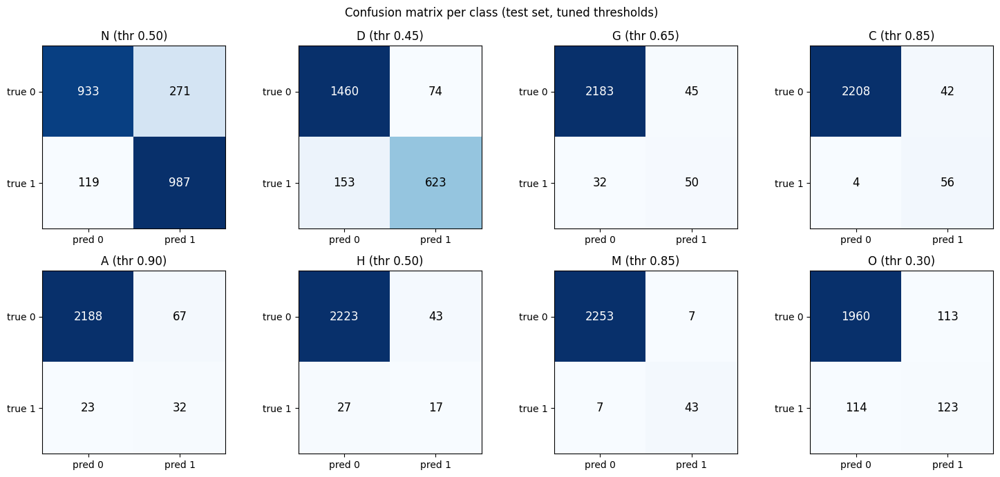

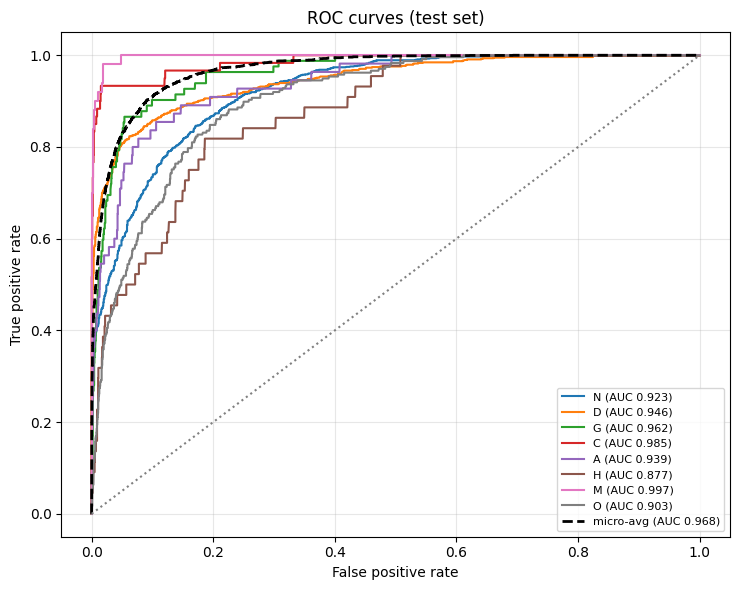

ODIR-only (1391) | acc 0.9055 | exact 0.5521 | P 0.5685 | R 0.6627 | F1 0.6016 | AUC 0.8919


In [32]:
# ============ CELL 8 : MODEL TESTING (per-class tuned thresholds | accuracy, recall, precision, F1, confusion matrix, ROC-AUC) ============
core(model).load_state_dict(torch.load(BEST_PT, map_location=DEVICE))                    # test with the BEST epoch weights

# ---- 1) VALIDATION probabilities (thresholds inga tune aagum, test-la illa) ----
va_loss, va_p, va_y = run_epoch(val_loader, False)

# ---- 2) per-class best threshold on VAL (maximise F1) ----
grid = np.arange(0.05, 0.96, 0.05)
THR = np.full(len(CLASSES), THRESHOLD, dtype=np.float32)                                 # default 0.5
for k, c in enumerate(CLASSES):
    if va_y[:, k].sum() < 5: continue                                                    # val-la rombha kammi positives -> 0.5 thaan
    f1s = [f1_score(va_y[:, k], (va_p[:, k] >= t).astype(int), zero_division=0) for t in grid]
    THR[k] = grid[int(np.argmax(f1s))]
# THR[CLASSES.index('N')] = 0.5                                                          # N-ku aggressive-ah irundha idha uncomment pannunga
print('tuned thresholds (val):', dict(zip(CLASSES, THR.round(2))))
json.dump(dict(zip(CLASSES, map(float, THR))), open(OUT_DIR / 'class_thresholds.json', 'w'), indent=2)

# ---- 3) TEST with tuned thresholds ----
te_loss, te_p, te_y = run_epoch(test_loader, False)
te_pred_05 = (te_p >= THRESHOLD).astype(int)                                             # old (0.5) -> comparison-ku mattum
te_pred    = (te_p >= THRESHOLD).astype(int)                                             # final = 0.5 (tuned gave no real gain)                                       # tuned -> ini ellame idha use pannum

def summ(pred, tag):
    print(f'{tag:8s} | acc {(pred == te_y).mean():.4f} | exact-match {(pred == te_y).all(1).mean():.4f} | '
          f'P {precision_score(te_y, pred, average="macro", zero_division=0):.4f} | '
          f'R {recall_score(te_y, pred, average="macro", zero_division=0):.4f} | '
          f'F1 {f1_score(te_y, pred, average="macro", zero_division=0):.4f}')
print(f'TEST ({len(te_y)} images) | loss {te_loss:.4f}')
summ(te_pred_05, 'thr=0.5'); summ(te_pred, 'tuned')

valid = [k for k in range(len(CLASSES)) if 0 < te_y[:, k].sum() < len(te_y)]              # classes present in test set (needed for AUC)
rows = []
for k, c in enumerate(CLASSES):
    rows.append(dict(cls=c, thr=float(THR[k]), support=int(te_y[:, k].sum()), accuracy=(te_pred[:, k] == te_y[:, k]).mean(),
                     precision=precision_score(te_y[:, k], te_pred[:, k], zero_division=0),
                     recall=recall_score(te_y[:, k], te_pred[:, k], zero_division=0),
                     f1=f1_score(te_y[:, k], te_pred[:, k], zero_division=0),
                     roc_auc=roc_auc_score(te_y[:, k], te_p[:, k]) if k in valid else np.nan))
res = pd.DataFrame(rows).round(4); res.to_csv(OUT_DIR / 'test_metrics_per_class.csv', index=False)
print(res.to_string(index=False)); print('macro ROC-AUC:', round(float(res.roc_auc.mean()), 4))
np.save(OUT_DIR / 'test_probs.npy', te_p); np.save(OUT_DIR / 'test_labels.npy', te_y)

# ---- confusion matrix (multi-label -> one 2x2 matrix per disease) ----
cms = multilabel_confusion_matrix(te_y, te_pred)
fig, axs = plt.subplots(2, 4, figsize=(15, 7))
for ax, cm, c in zip(axs.ravel(), cms, CLASSES):
    ax.imshow(cm, cmap='Blues'); ax.set_title(f'{c} (thr {THR[CLASSES.index(c)]:.2f})'); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['pred 0', 'pred 1']); ax.set_yticklabels(['true 0', 'true 1'])
    for i in range(2):
        for j in range(2): ax.text(j, i, int(cm[i, j]), ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
plt.suptitle('Confusion matrix per class (test set, tuned thresholds)'); plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'confusion_matrix.png', dpi=130); plt.show()

# ---- ROC curves + AUC ----
plt.figure(figsize=(7.5, 6))
for k in valid:
    fpr, tpr, _ = roc_curve(te_y[:, k], te_p[:, k]); plt.plot(fpr, tpr, lw=1.5, label=f'{CLASSES[k]} (AUC {auc(fpr, tpr):.3f})')
fpr, tpr, _ = roc_curve(te_y[:, valid].ravel(), te_p[:, valid].ravel()); plt.plot(fpr, tpr, 'k--', lw=2, label=f'micro-avg (AUC {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], ':', c='gray'); plt.xlabel('False positive rate'); plt.ylabel('True positive rate')
plt.title('ROC curves (test set)'); plt.legend(fontsize=8, loc='lower right'); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'roc_auc.png', dpi=130); plt.show()
    # ---- ODIR-only test (clean benchmark number) ----
odir_m = (te_df.source == 'odir').values
p_o, y_o = te_p[odir_m], te_y[odir_m]
pred_o = (p_o >= THRESHOLD).astype(int)
ok = [k for k in range(8) if 0 < y_o[:, k].sum() < len(y_o)]
print(f'ODIR-only ({odir_m.sum()}) | acc {(pred_o==y_o).mean():.4f} | exact {(pred_o==y_o).all(1).mean():.4f} | '
      f'P {precision_score(y_o, pred_o, average="macro", zero_division=0):.4f} | R {recall_score(y_o, pred_o, average="macro", zero_division=0):.4f} | '
      f'F1 {f1_score(y_o, pred_o, average="macro", zero_division=0):.4f} | AUC {np.mean([roc_auc_score(y_o[:,k], p_o[:,k]) for k in ok]):.4f}')

In [33]:
print(va_df.source.value_counts(), te_df.source.value_counts())
print(va_df[CLASSES].sum(), te_df[CLASSES].sum())

source
odir      698
aptos     366
idrid      50
refuge     40
Name: count, dtype: int64 source
odir      1391
aptos      736
idrid      104
refuge      79
Name: count, dtype: int64
N    550
D    400
G     37
C     29
A     29
H      4
M     28
O    119
dtype: int64 N    1106
D     776
G      82
C      60
A      55
H      44
M      50
O     237
dtype: int64


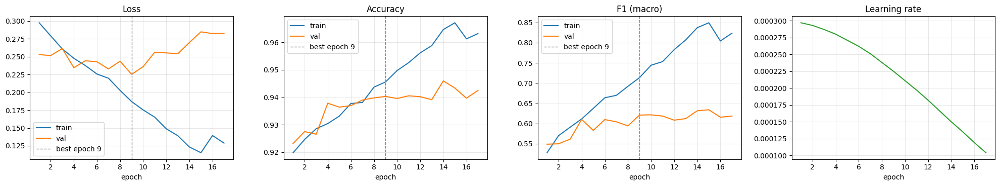

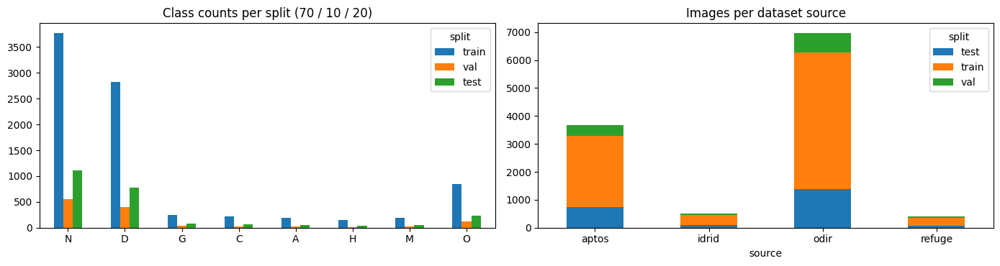

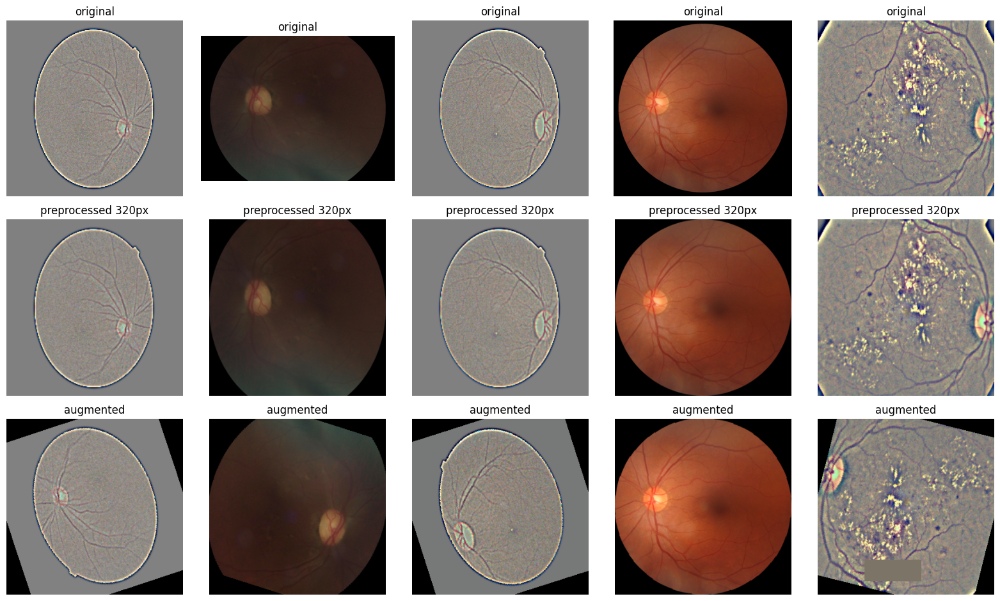

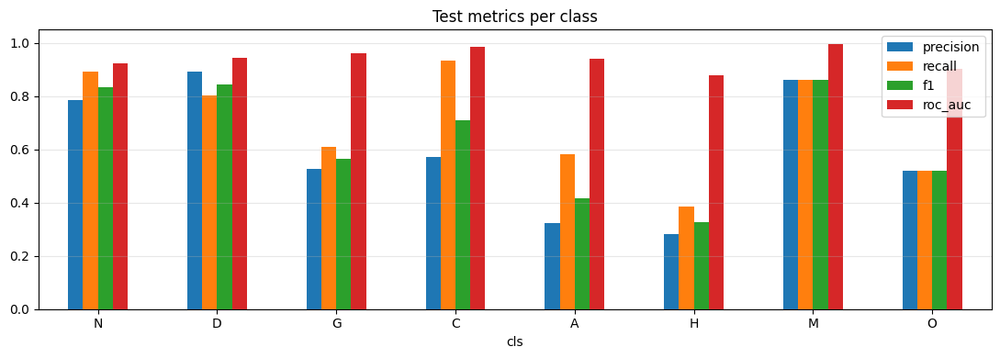

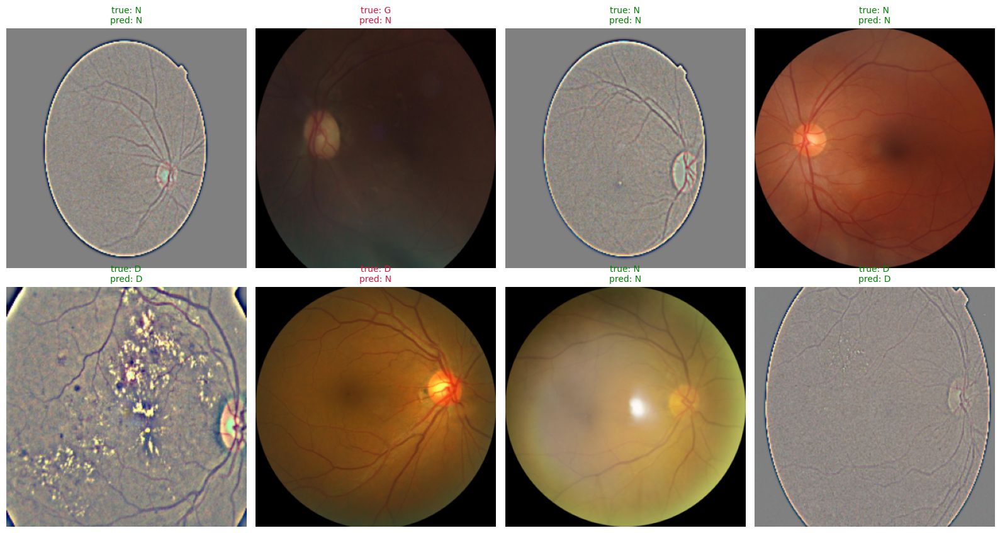

In [34]:
# ============ CELL 9 : VISUALIZATION ============
log = pd.read_csv(LOG_CSV); be = int(json.load(open(OUT_DIR / 'training_summary.json'))['best_epoch'])

# 1) training curves: loss / accuracy / F1 / learning-rate
fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
for a, (tr, va, t) in zip(ax[:3], [('train_loss', 'val_loss', 'Loss'), ('train_acc', 'val_acc', 'Accuracy'), ('train_f1', 'val_f1', 'F1 (macro)')]):
    a.plot(log.epoch, log[tr], label='train'); a.plot(log.epoch, log[va], label='val'); a.axvline(be, c='gray', ls='--', lw=1, label=f'best epoch {be}')
    a.set_title(t); a.set_xlabel('epoch'); a.legend(); a.grid(alpha=.3)
ax[3].plot(log.epoch, log.lr, c='tab:green'); ax[3].set_title('Learning rate'); ax[3].set_xlabel('epoch'); ax[3].grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'training_curves.png', dpi=130); plt.show()

# 2) dataset: class counts per split, images per source
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
df.groupby('split')[CLASSES].sum().loc[['train', 'val', 'test']].T.plot.bar(ax=ax[0], rot=0); ax[0].set_title('Class counts per split (70 / 10 / 20)')
df.groupby(['source', 'split']).size().unstack(fill_value=0).plot.bar(ax=ax[1], stacked=True, rot=0); ax[1].set_title('Images per dataset source')
plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'dataset_overview.png', dpi=130); plt.show()

# 3) preprocessing: original -> resized/grayscale -> augmented
def denorm(t): return (t.permute(1, 2, 0).numpy() * np.array(STD) + np.array(MEAN)).clip(0, 1)
samp = te_df.sample(min(5, len(te_df)), random_state=SEED)
fig, ax = plt.subplots(3, len(samp), figsize=(3.2 * len(samp), 9.5), squeeze=False)
for j, r in enumerate(samp.itertuples()):
    im = Image.open(r.path); im.draft('RGB', (IMG_SIZE * 2, IMG_SIZE * 2)); im = im.convert('RGB')
    ax[0, j].imshow(im); ax[0, j].set_title('original'); ax[1, j].imshow(denorm(TF['test'](im)), cmap='gray'); ax[1, j].set_title(f'preprocessed {IMG_SIZE}px')
    ax[2, j].imshow(denorm(TF['train'](im)), cmap='gray'); ax[2, j].set_title('augmented')
    for i in range(3): ax[i, j].axis('off')
plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'preprocessing_samples.png', dpi=110); plt.show()

# 4) per-class F1 / recall / AUC bars
res.set_index('cls')[['precision', 'recall', 'f1', 'roc_auc']].plot.bar(figsize=(11, 4), rot=0, ylim=(0, 1.05)); plt.title('Test metrics per class')
plt.grid(alpha=.3, axis='y'); plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'per_class_metrics.png', dpi=130); plt.show()

# 5) sample test predictions (true vs predicted labels)
idx = np.random.RandomState(SEED).choice(len(te_df), min(8, len(te_df)), replace=False)
fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))
for a, i in zip(ax.ravel(), idx):
    img, _ = FundusDS(te_df, 'test')[i]; a.imshow(denorm(img), cmap='gray'); a.axis('off')
    tl = ','.join(c for c, v in zip(CLASSES, te_y[i]) if v) or '-'; pl = ','.join(c for c, v in zip(CLASSES, te_pred[i]) if v) or '-'
    a.set_title(f'true: {tl}\npred: {pl}', color='green' if tl == pl else 'crimson', fontsize=10)
plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'sample_predictions.png', dpi=110); plt.show()

graded images -> train 2922 | val 416 | test 840
grade   No DR  Mild  Moderate  Severe  Proliferative
source                                              
aptos    1256   268       689     138            209
idrid     111    19       121      67             44
class weights: {'No DR': np.float32(1.0), 'Mild': np.float32(2.18), 'Moderate': np.float32(1.3), 'Severe': np.float32(2.58), 'Proliferative': np.float32(2.32)}
ep 01/25 | loss 1.1619/1.1091 | acc 0.660/0.707 | QWK 0.666/0.801 (train/val) | 84s  <- best
ep 02/25 | loss 1.0000/0.9922 | acc 0.728/0.740 | QWK 0.788/0.802 (train/val) | 76s  <- best
ep 03/25 | loss 0.9544/0.9944 | acc 0.759/0.767 | QWK 0.813/0.838 (train/val) | 78s  <- best
ep 04/25 | loss 0.9081/0.9405 | acc 0.769/0.784 | QWK 0.840/0.841 (train/val) | 74s  <- best
ep 05/25 | loss 0.8846/1.0797 | acc 0.779/0.769 | QWK 0.845/0.824 (train/val) | 74s
ep 06/25 | loss 0.8631/1.0351 | acc 0.789/0.769 | QWK 0.841/0.827 (train/val) | 73s
ep 07/25 | loss 0.8357/0.9810 | acc 0.8

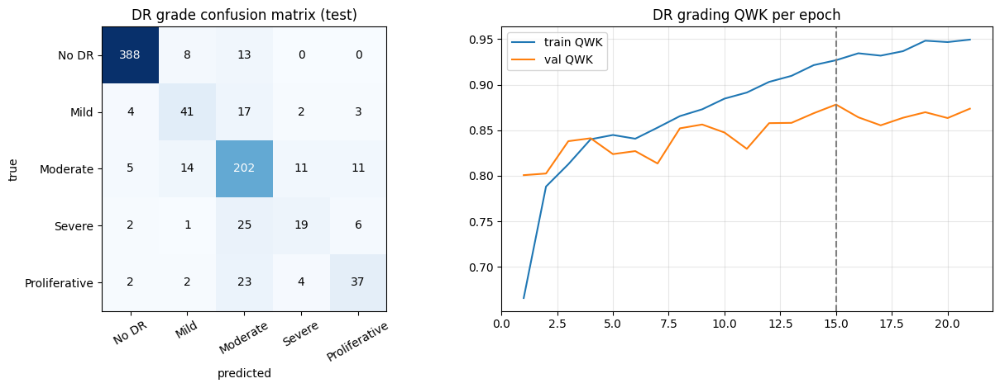

saved: /kaggle/working/outputs/best_grade_model.pth (Kaggle: right panel -> Output tab)


/kaggle/working/outputs/best_grade_model.pth

saved: /kaggle/working/outputs/grade_training_log.csv (Kaggle: right panel -> Output tab)


/kaggle/working/outputs/grade_training_log.csv

In [35]:
# ============ CELL 10 : DR SEVERITY MODEL  (grade 0-4 = No DR / Mild / Moderate / Severe / Proliferative) ============
GRADE_NAMES = ['No DR', 'Mild', 'Moderate', 'Severe', 'Proliferative']
GR_SIZE, GR_EPOCHS, GR_BS, GR_LR, GR_PAT = 384, 25, 16, 2e-4, 6
GR_BEST, GR_LOG = OUT_DIR / 'best_grade_model.pth', OUT_DIR / 'grade_training_log.csv'
if USE_CUDA: torch.cuda.empty_cache()

# same patient-level split as the classifier (no leakage); only images that have a DR grade
g_tr, g_va, g_te = [d[d.grade >= 0].reset_index(drop=True) for d in (tr_df, va_df, te_df)]
assert len(g_tr) > 0, 'no graded images found (APTOS / IDRiD Part B / FGADR needed)'
print(f'graded images -> train {len(g_tr)} | val {len(g_va)} | test {len(g_te)}')
print(pd.crosstab(g_tr.source, g_tr.grade).rename(columns=dict(enumerate(GRADE_NAMES))))

GR_AUG  = T.Compose([T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(25), T.ColorJitter(brightness=0.2, contrast=0.2)])
GR_NORM = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
_crop = CropBlack()
def grade_prep(pil, train=False):
    """crop black border -> resize -> Ben Graham filter (removes lighting differences so MA / haemorrhage / exudate stand out)"""
    im = _crop(pil.convert('RGB')).resize((GR_SIZE, GR_SIZE), Image.BILINEAR)
    a = np.array(im); a = cv2.addWeighted(a, 4, cv2.GaussianBlur(a, (0, 0), GR_SIZE / 30), -4, 128)
    im = Image.fromarray(a)
    return GR_NORM(GR_AUG(im) if train else im)

class GradeDS(Dataset):
    def __init__(self, d, train): self.p, self.y, self.train = d.path.values, d.grade.values.astype(np.int64), train
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        im = Image.open(self.p[i])
        try: im.draft('RGB', (GR_SIZE * 2, GR_SIZE * 2))
        except Exception: pass
        return grade_prep(im.convert('RGB'), self.train), int(self.y[i])

_nw = min(NUM_WORKERS, os.cpu_count() or 1); _kw = dict(num_workers=_nw, pin_memory=USE_CUDA, persistent_workers=False)
gr_train = DataLoader(GradeDS(g_tr, True),  batch_size=GR_BS, shuffle=True, drop_last=True, **_kw)
gr_val   = DataLoader(GradeDS(g_va, False), batch_size=GR_BS * 2, shuffle=False, **_kw)
gr_test  = DataLoader(GradeDS(g_te, False), batch_size=GR_BS * 2, shuffle=False, **_kw)

grade_model = make_densenet('DR grade', num_classes=5, drop_rate=0.3).to(DEVICE, memory_format=torch.channels_last)
cnt = np.bincount(g_tr.grade.values, minlength=5).astype(np.float64)
cw  = torch.tensor(np.clip(np.sqrt(cnt.max() / np.maximum(cnt, 1)), 1.0, 5.0), dtype=torch.float32, device=DEVICE)     # rare grades weigh more
gr_crit   = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.05)
gr_opt    = torch.optim.AdamW(grade_model.parameters(), lr=GR_LR, weight_decay=1e-4)
gr_sched  = torch.optim.lr_scheduler.CosineAnnealingLR(gr_opt, T_max=GR_EPOCHS, eta_min=1e-6)
gr_scaler = torch.amp.GradScaler('cuda', enabled=USE_CUDA)
print('class weights:', dict(zip(GRADE_NAMES, cw.cpu().numpy().round(2))))

def gr_epoch(loader, train):
    grade_model.train(train); tot, n, P, Y = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x = x.to(DEVICE, non_blocking=True).contiguous(memory_format=torch.channels_last); y = y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE_TYPE, dtype=torch.float16, enabled=USE_CUDA): lg = grade_model(x)
            loss = gr_crit(lg.float(), y)
            if train:
                gr_opt.zero_grad(set_to_none=True); gr_scaler.scale(loss).backward(); gr_scaler.unscale_(gr_opt)
                nn.utils.clip_grad_norm_(grade_model.parameters(), 1.0); gr_scaler.step(gr_opt); gr_scaler.update()
            tot += loss.item() * len(x); n += len(x); P.append(torch.softmax(lg.float(), 1).detach().cpu()); Y.append(y.cpu())
    return tot / max(n, 1), torch.cat(P).numpy(), torch.cat(Y).numpy()

qwk = lambda y, p: float(cohen_kappa_score(y, p.argmax(1), weights='quadratic'))      # quadratic weighted kappa: standard DR-grading metric
with open(GR_LOG, 'w', newline='') as f: csv.writer(f).writerow(['epoch', 'train_loss', 'val_loss', 'train_acc', 'val_acc', 'train_qwk', 'val_qwk', 'lr'])
best_q, best_e, bad, t_start = -1.0, 0, 0, time.time()
for ep in range(1, GR_EPOCHS + 1):
    t0 = time.time(); trl, trp, try_ = gr_epoch(gr_train, True); val, vap, vay = gr_epoch(gr_val, False); gr_sched.step()
    ta, va_ = float((trp.argmax(1) == try_).mean()), float((vap.argmax(1) == vay).mean()); tq, vq = qwk(try_, trp), qwk(vay, vap)
    with open(GR_LOG, 'a', newline='') as f: csv.writer(f).writerow([ep, round(trl, 5), round(val, 5), round(ta, 4), round(va_, 4), round(tq, 4), round(vq, 4), gr_opt.param_groups[0]['lr']])
    star = ''
    if vq > best_q: best_q, best_e, bad = vq, ep, 0; torch.save(grade_model.state_dict(), GR_BEST); star = '  <- best'
    else: bad += 1
    print(f'ep {ep:02d}/{GR_EPOCHS} | loss {trl:.4f}/{val:.4f} | acc {ta:.3f}/{va_:.3f} | QWK {tq:.3f}/{vq:.3f} (train/val) | {time.time() - t0:.0f}s{star}')
    if bad >= GR_PAT: print(f'early stopping at epoch {ep}'); break
print(f'\ngrade model: best epoch {best_e} (val QWK {best_q:.4f}) | {(time.time() - t_start) / 60:.1f} min')

# ---- test ----
grade_model.load_state_dict(torch.load(GR_BEST, map_location=DEVICE))
_, tp, ty = gr_epoch(gr_test, False); pred = tp.argmax(1)
print(f'\nGRADE TEST ({len(ty)} images) | accuracy {(pred == ty).mean():.4f} | QWK {qwk(ty, tp):.4f} | within-1-grade {(np.abs(pred - ty) <= 1).mean():.4f}')
cm = confusion_matrix(ty, pred, labels=range(5)); rec = cm.diagonal() / np.maximum(cm.sum(1), 1)
print('recall per grade:', dict(zip(GRADE_NAMES, rec.round(3))))
for s in sorted(g_te.source.unique()):
    m_ = (g_te.source == s).values
    if m_.sum() > 5: print(f'  {s:6s} n={m_.sum():4d} | acc {(pred[m_] == ty[m_]).mean():.3f} | QWK {qwk(ty[m_], tp[m_]):.3f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8)); ax[0].imshow(cm, cmap='Blues'); ax[0].set_xticks(range(5)); ax[0].set_yticks(range(5))
ax[0].set_xticklabels(GRADE_NAMES, rotation=30); ax[0].set_yticklabels(GRADE_NAMES); ax[0].set_xlabel('predicted'); ax[0].set_ylabel('true'); ax[0].set_title('DR grade confusion matrix (test)')
for i in range(5):
    for j in range(5): ax[0].text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
gl = pd.read_csv(GR_LOG); ax[1].plot(gl.epoch, gl.train_qwk, label='train QWK'); ax[1].plot(gl.epoch, gl.val_qwk, label='val QWK'); ax[1].axvline(best_e, c='gray', ls='--')
ax[1].set_title('DR grading QWK per epoch'); ax[1].legend(); ax[1].grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'grade_results.png', dpi=130); plt.show()
for f in (GR_BEST, GR_LOG): download_file(f)


In [36]:
# ============ CELL 11 : SEGMENTATION DATA  (IDRiD: MA/HE/EX/SE lesions + optic disc | REFUGE: optic disc + cup) ============
import cv2
from concurrent.futures import ThreadPoolExecutor
SEG_SIZE       = 512                                   # segmentation needs higher resolution than classification (lesions are tiny)
SEG_CH         = ['MA', 'HE', 'EX', 'SE', 'OD', 'OC', 'IRMA', 'NV']   # microaneurysm, haemorrhage, hard exudate, soft exudate, optic disc, optic cup, IRMA, new vessels (IRMA/NV only if FGADR has those masks)
NSEG           = len(SEG_CH)
MAX_FGADR_SEG  = 1000                                  # how many FGADR / DDR images to keep in RAM (each ~2.8 MB; lower these if RAM is low)
MAX_DDR_SEG    = 600
MAX_REFUGE_SEG = 500                                   # how many REFUGE images to use for segmentation (RAM / time)
SEG_MEAN, SEG_STD = np.array(MEAN, np.float32), np.array(STD, np.float32)

def read_rgb(path):
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is None: img = np.array(Image.open(path).convert('RGB'))[:, :, ::-1]
    return cv2.cvtColor(np.ascontiguousarray(img), cv2.COLOR_BGR2RGB)
def read_mask(path):
    m = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if m is None: m = np.array(Image.open(path))
    return m.max(axis=2) if m.ndim == 3 else m
def fundus_box(img, thr=12):
    g = img.max(2) > thr; r, c = np.where(g.mean(1) > 0.02)[0], np.where(g.mean(0) > 0.02)[0]
    if len(r) < 50 or len(c) < 50: return (0, 0, img.shape[1], img.shape[0])
    return (int(c[0]), int(r[0]), int(c[-1]) + 1, int(r[-1]) + 1)
def crop_resize(a, box, interp):
    x0, y0, x1, y1 = box; return cv2.resize(a[y0:y1, x0:x1], (SEG_SIZE, SEG_SIZE), interpolation=interp)
def prep_seg_image(img):
    box = fundus_box(img); return crop_resize(img, box, cv2.INTER_AREA), box
def fit_mask(m, img): return m if m.shape[:2] == img.shape[:2] else cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)

# ---------- IDRiD Part A ----------
def find_idrid_seg(root):
    imgs, masks = {}, {}
    for p in index_images(root):
        if 'segmentation' not in str(p).lower(): continue
        m = re.match(r'idrid_(\d+)\.(jpg|jpeg|png)$', p.name, re.I)
        if m: imgs[m.group(1)] = p
        m2 = re.match(r'idrid_(\d+)_(ma|he|ex|se|od)\.(tif|tiff|png|jpg)$', p.name, re.I)
        if m2: masks.setdefault(m2.group(1), {})[m2.group(2).upper()] = p
    return [(k, p, masks.get(k, {})) for k, p in sorted(imgs.items())]

def load_idrid_item(args):
    k, ip, md = args
    img = read_rgb(ip); box = fundus_box(img); msk = np.zeros((SEG_SIZE, SEG_SIZE, NSEG), np.uint8)
    for ci, nm in enumerate(['MA', 'HE', 'EX', 'SE', 'OD']):          # a missing lesion file = image has no such lesion
        if nm in md: msk[..., ci] = crop_resize((fit_mask(read_mask(md[nm]), img) > 0).astype(np.uint8), box, cv2.INTER_NEAREST)
    av = np.array([1, 1, 1, 1, 1 if 'OD' in md else 0, 0, 0, 0], np.float32)
    return dict(img=crop_resize(img, box, cv2.INTER_AREA), msk=msk, avail=av, src='idrid', name=f'IDRiD_{k}')

# ---------- REFUGE ----------
def refuge_disc_cup(m):
    """REFUGE masks: 255 = background, 128 = disc, 0 = cup (some copies use 0 = background, 128 = disc, 255 = cup, or 0/1/2)"""
    u = set(np.unique(m).tolist())
    if 128 in u:
        if (m == 255).mean() >= (m == 0).mean(): return m <= 128, m == 0
        return m > 0, m == 255
    if m.max() <= 2 and 2 in u: return m > 0, m == 2
    return m > 0, None                                                    # disc only

def find_refuge_pairs(root):
    files = index_images(root)
    masks = [p for p in files if any(w in '/'.join(p.relative_to(root).parts[:-1]).lower() for w in MASK_WORDS)] or [p for p in files if p.suffix.lower() == '.bmp']
    ms = set(masks); norm = lambda p: re.sub(r'[_-]?(mask|seg|gt|label)$', '', p.stem.lower())
    mk = {norm(p): p for p in masks}; pairs = {}
    for p in files:
        if p in ms: continue
        key = norm(p)
        if key in mk and (key not in pairs or p.suffix.lower() in ('.jpg', '.jpeg')): pairs[key] = (key, p, mk[key])
    return list(pairs.values())

def load_refuge_item(args):
    key, ip, mp = args
    try:
        img = read_rgb(ip); box = fundus_box(img); disc, cup = refuge_disc_cup(fit_mask(read_mask(mp), img))
        msk = np.zeros((SEG_SIZE, SEG_SIZE, NSEG), np.uint8); av = np.zeros(NSEG, np.float32)
        msk[..., 4] = crop_resize((disc | (cup if cup is not None else False)).astype(np.uint8), box, cv2.INTER_NEAREST); av[4] = 1
        if cup is not None: msk[..., 5] = crop_resize(cup.astype(np.uint8), box, cv2.INTER_NEAREST); av[5] = 1
        return dict(img=crop_resize(img, box, cv2.INTER_AREA), msk=msk, avail=av, src='refuge', name=key)
    except Exception: return None

# ---------- lesion-mask datasets found by folder-name keyword : FGADR (MA/HE/EX/SE + IRMA/NV) and DDR (MA/HE/EX/SE) ----------
FG_KEYS = {'MA': ('microaneurysm',), 'HE': ('hemohedge', 'hemorrhage', 'haemorrhage', 'hemo'), 'EX': ('hardexudate', 'hard_exudate', 'hard exudate'),
           'SE': ('softexudate', 'soft_exudate', 'soft exudate'), 'IRMA': ('irma',), 'NV': ('neovasc',)}
def fgadr_lesion(parts):
    folder = '/'.join(parts).lower()
    return next((c for c, ks in FG_KEYS.items() if any(k in folder for k in ks)), None)

def ddr_lesion(parts):
    for part in reversed(parts):
        q = part.lower()
        if q in ('ma', 'he', 'ex', 'se'): return q.upper()
        if 'microaneurysm' in q: return 'MA'
        if 'hemorrhage' in q or 'haemorrhage' in q: return 'HE'
        if 'exudate' in q: return 'SE' if 'soft' in q else 'EX'
        if 'cotton' in q: return 'SE'
    return None

def find_mask_sets(root, lesion_of, src):
    imgs, masks = {}, {c: {} for c in SEG_CH}
    for p in index_images(root):
        parts = p.relative_to(root).parts[:-1]; cls = lesion_of(parts)
        if cls: masks[cls][p.stem.lower()] = p
        elif not any(w in '/'.join(parts).lower() for w in ('mask', 'label')): imgs.setdefault(p.stem.lower(), p)
    have = {c for c in SEG_CH if masks[c]}
    print(f'{src.upper()} mask folders found:', {c: len(masks[c]) for c in SEG_CH if masks[c]}, '| photos:', len(imgs))
    keep = {k: p for k, p in imgs.items() if any(k in masks[c] for c in have)}          # photos that own at least one lesion mask
    if not keep: print(f'  WARNING: {src} has no photo with a matching lesion mask (names differ, or this copy has no masks). photo e.g.', list(imgs)[:2], '| mask e.g.', [list(masks[c])[:1] for c in have][:2])
    return [(k, p, {c: masks[c][k] for c in have if k in masks[c]}, have, src) for k, p in sorted(keep.items())]

def load_mask_item(args):
    k, ip, md, have, src = args
    try:
        img = read_rgb(ip); box = fundus_box(img); msk = np.zeros((SEG_SIZE, SEG_SIZE, NSEG), np.uint8); av = np.zeros(NSEG, np.float32)
        for c in have:                                                   # a lesion type with a mask folder but no file for this photo = lesion absent
            ci = SEG_CH.index(c); av[ci] = 1
            if c in md: msk[..., ci] = crop_resize((fit_mask(read_mask(md[c]), img) > 0).astype(np.uint8), box, cv2.INTER_NEAREST)
        return dict(img=crop_resize(img, box, cv2.INTER_AREA), msk=msk, avail=av, src=src, name=f'{src.upper()}_{k}')
    except Exception: return None

ITEMS = []
with ThreadPoolExecutor(max_workers=4) as ex:
    if 'idrid' in PATHS:
        jobs = find_idrid_seg(PATHS['idrid']); print(f'IDRiD Part A: {len(jobs)} images with masks')
        ITEMS += [r for r in tqdm(ex.map(load_idrid_item, jobs), total=len(jobs), desc='IDRiD seg') if r]
    if 'refuge' in PATHS:
        jobs = find_refuge_pairs(PATHS['refuge']); random.Random(SEED).shuffle(jobs); jobs = jobs[:MAX_REFUGE_SEG]
        print(f'REFUGE: {len(jobs)} image/mask pairs used')
        ITEMS += [r for r in tqdm(ex.map(load_refuge_item, jobs), total=len(jobs), desc='REFUGE seg') if r]
    for _src, _lf, _mx in (('fgadr', fgadr_lesion, MAX_FGADR_SEG), ('ddr', ddr_lesion, MAX_DDR_SEG)):
        if _src in PATHS:
            jobs = find_mask_sets(PATHS[_src], _lf, _src); random.Random(SEED).shuffle(jobs); jobs = jobs[:_mx]
            print(f'{_src.upper()}: {len(jobs)} image/mask sets used')
            ITEMS += [r for r in tqdm(ex.map(load_mask_item, jobs), total=len(jobs), desc=_src + ' seg') if r]
assert ITEMS, 'no segmentation data found - check the folder printout in Cell 2 (IDRiD needs "A. Segmentation", REFUGE needs images + masks)'

# ---------- split 70 / 20 / 10 inside every source ----------
rng = np.random.RandomState(SEED); SEG = {'train': [], 'val': [], 'test': []}
for src in sorted({i['src'] for i in ITEMS}):
    its = [i for i in ITEMS if i['src'] == src]; perm = rng.permutation(len(its)); n_te, n_va = int(round(0.2 * len(its))), int(round(0.1 * len(its)))
    for j, kk in enumerate(perm): SEG['test' if j < n_te else 'val' if j < n_te + n_va else 'train'].append(its[kk])
for s in SEG: print(f'{s:5s}: {len(SEG[s]):4d} images', {src: sum(i["src"] == src for i in SEG[s]) for src in sorted({i["src"] for i in ITEMS})})
print('mask pixel fraction per structure:', {c: round(float(np.mean([i['msk'][..., k].mean() for i in ITEMS if i['avail'][k]] or [0])), 5) for k, c in enumerate(SEG_CH)})

# ---------- Dataset with augmentation (flip, rotate, scale, brightness/contrast; image + mask transformed together) ----------
def warp_mask(m, M):
    out = np.zeros_like(m)
    for s in range(0, m.shape[2], 3): out[..., s:s + 3] = cv2.warpAffine(np.ascontiguousarray(m[..., s:s + 3]), M, (SEG_SIZE, SEG_SIZE), flags=cv2.INTER_NEAREST, borderValue=0).reshape(SEG_SIZE, SEG_SIZE, -1)
    return out

class SegDS(Dataset):
    def __init__(self, items, train): self.items, self.train = items, train
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        it = self.items[i]; img, m = it['img'], it['msk']
        if self.train:
            if random.random() < 0.5: img, m = img[:, ::-1], m[:, ::-1]
            if random.random() < 0.5: img, m = img[::-1], m[::-1]
            M = cv2.getRotationMatrix2D((SEG_SIZE / 2, SEG_SIZE / 2), random.uniform(-25, 25), random.uniform(0.9, 1.1))
            img = cv2.warpAffine(np.ascontiguousarray(img), M, (SEG_SIZE, SEG_SIZE), flags=cv2.INTER_LINEAR, borderValue=0); m = warp_mask(np.ascontiguousarray(m), M)
            img = np.clip(img.astype(np.float32) * random.uniform(0.8, 1.2) + random.uniform(-15, 15), 0, 255)
        x = (img.astype(np.float32) / 255.0 - SEG_MEAN) / SEG_STD
        return torch.from_numpy(np.ascontiguousarray(x.transpose(2, 0, 1))), torch.from_numpy(np.ascontiguousarray(m.transpose(2, 0, 1))).float(), torch.from_numpy(it['avail'])

IDRiD Part A: 81 images with masks


IDRiD seg:   0%|          | 0/81 [00:00<?, ?it/s]

REFUGE: 500 image/mask pairs used


REFUGE seg:   0%|          | 0/500 [00:00<?, ?it/s]

train:  407 images {'idrid': 57, 'refuge': 350}
val  :   58 images {'idrid': 8, 'refuge': 50}
test :  116 images {'idrid': 16, 'refuge': 100}
mask pixel fraction per structure: {'MA': 0.0013, 'HE': 0.01261, 'EX': 0.02316, 'SE': 0.00233, 'OD': 0.01734, 'OC': 0.00427, 'IRMA': 0.0, 'NV': 0.0}


In [37]:
# ============ CELL 12 : SEGMENTATION MODEL (U-Net with DenseNet121 encoder) + HYPER-PARAMETERS ============
import torch.nn.functional as F
from torch.utils.data import WeightedRandomSampler

class ConvBlock(nn.Module):
    def __init__(self, i, o):
        super().__init__()
        self.b = nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True),
                               nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))
    def forward(self, x): return self.b(x)

class DenseUNet(nn.Module):
    """DenseNet121 encoder (same backbone family as the classifier) + U-Net decoder -> 8 channels (MA, HE, EX, SE, OD, OC, IRMA, NV)"""
    def __init__(self, n_out=6, pretrained=True):
        super().__init__()
        self.enc = make_densenet('seg encoder', features_only=True)
        ch = self.enc.feature_info.channels(); dec_ch = [256, 128, 64, 32]; self.dec = nn.ModuleList(); cur = ch[-1]
        for skip, o in zip(reversed(ch[:-1]), dec_ch): self.dec.append(ConvBlock(cur + skip, o)); cur = o
        self.refine = ConvBlock(cur, 32); self.head = nn.Conv2d(32, n_out, 1)
    def forward(self, x):
        f = self.enc(x); y = f[-1]
        for blk, skip in zip(self.dec, reversed(f[:-1])):
            y = blk(torch.cat([F.interpolate(y, size=skip.shape[-2:], mode='bilinear', align_corners=False), skip], 1))
        y = F.interpolate(y, size=x.shape[-2:], mode='bilinear', align_corners=False)      # back to full resolution
        return self.head(self.refine(y))

seg_model = DenseUNet(len(SEG_CH)).to(DEVICE, memory_format=torch.channels_last)
print(f'DenseUNet params: {sum(p.numel() for p in seg_model.parameters()) / 1e6:.1f} M | input {SEG_SIZE}x{SEG_SIZE} | outputs {SEG_CH}')

# ---- hyper-parameters ----
SEG_EPOCHS, SEG_BS, SEG_LR, SEG_WD, SEG_PATIENCE = 60, 4, 3e-4, 1e-4, 12
SEG_SAMPLES_PER_EPOCH = 480            # per epoch: ~half IDRiD, ~half REFUGE (IDRiD is small, so its images are repeated)
POSW = torch.tensor([20., 8., 6., 10., 1., 2., 8., 8.], device=DEVICE)       # small lesions get more weight

n_src = {s: sum(i['src'] == s for i in SEG['train']) for s in {i['src'] for i in SEG['train']}}
w = [1.0 / n_src[i['src']] ** 0.5 for i in SEG['train']]                    # every source gets the same share of each epoch
kw = dict(num_workers=min(NUM_WORKERS, 2), pin_memory=USE_CUDA, persistent_workers=False)
seg_train_loader = DataLoader(SegDS(SEG['train'], True), batch_size=SEG_BS, sampler=WeightedRandomSampler(w, SEG_SAMPLES_PER_EPOCH, replacement=True), drop_last=True, **kw)
seg_val_loader   = DataLoader(SegDS(SEG['val'], False),  batch_size=SEG_BS, shuffle=False, **kw)
seg_test_loader  = DataLoader(SegDS(SEG['test'], False), batch_size=SEG_BS, shuffle=False, **kw)

def seg_loss(logits, y, avail):
    """BCE (pos-weighted) + soft Dice; each sample only supervises the structures its dataset annotates (avail)"""
    wgt = avail[:, :, None, None]
    bce = F.binary_cross_entropy_with_logits(logits, y, pos_weight=POSW[None, :, None, None], reduction='none')
    bce = (bce * wgt).sum() / (wgt.sum() * y.shape[2] * y.shape[3]).clamp(min=1)
    p = torch.sigmoid(logits) * wgt; yy = y * wgt
    inter, den = (p * yy).sum((0, 2, 3)), p.sum((0, 2, 3)) + yy.sum((0, 2, 3))
    present = (avail.sum(0) > 0).float(); dice = (1 - (2 * inter + 1) / (den + 1))
    return bce + (dice * present).sum() / present.sum().clamp(min=1)

seg_opt   = torch.optim.AdamW(seg_model.parameters(), lr=SEG_LR, weight_decay=SEG_WD)
seg_sched = torch.optim.lr_scheduler.CosineAnnealingLR(seg_opt, T_max=SEG_EPOCHS, eta_min=1e-6)
seg_scaler = torch.amp.GradScaler('cuda', enabled=USE_CUDA)
print(f'epochs {SEG_EPOCHS} | batch {SEG_BS} | lr {SEG_LR} (cosine) | AdamW | {SEG_SAMPLES_PER_EPOCH} samples/epoch | early-stop patience {SEG_PATIENCE}')
if USE_CUDA: print(f'VRAM now: {torch.cuda.memory_allocated() / 1e9:.2f} GB')

DenseUNet params: 13.6 M | input 512x512 | outputs ['MA', 'HE', 'EX', 'SE', 'OD', 'OC', 'IRMA', 'NV']
epochs 60 | batch 4 | lr 0.0003 (cosine) | AdamW | 480 samples/epoch | early-stop patience 12
VRAM now: 0.34 GB


In [38]:
print("Testing segmentation batch...")

t0 = time.time()
xb, yb, ab = next(iter(seg_train_loader))

print("Batch loaded!")
print("X shape:", xb.shape)
print("Y shape:", yb.shape)
print("Available shape:", ab.shape)
print("Time:", round(time.time() - t0, 2), "sec")

Testing segmentation batch...
Batch loaded!
X shape: torch.Size([4, 3, 512, 512])
Y shape: torch.Size([4, 8, 512, 512])
Available shape: torch.Size([4, 8])
Time: 1.29 sec


In [41]:
# ============ CELL 13 (replacement) : paths of the already-trained segmentation model ============
SEG_LOG   = OUT_DIR / 'seg_training_log.csv'
SEG_BEST  = OUT_DIR / 'best_seg_model.pth'
SEG_FINAL = OUT_DIR / 'final_seg_model.pth'
assert SEG_BEST.exists(), 'best_seg_model.pth not found in OUT_DIR - copy it there first'
assert SEG_LOG.exists(),  'seg_training_log.csv not found in OUT_DIR - copy it there first'

tuned thresholds (val): {'MA': 0.4, 'HE': 0.9, 'EX': 0.65, 'SE': 0.2, 'OD': 0.2, 'OC': 0.25, 'IRMA': 0.5, 'NV': 0.5}
source structure  n_images   dice    iou  precision  recall
 idrid        MA        16 0.3903 0.2425     0.3640  0.4208
 idrid        HE        16 0.6405 0.4712     0.6579  0.6241
 idrid        EX        16 0.7048 0.5442     0.6801  0.7314
 idrid        SE        16 0.5910 0.4195     0.7640  0.4819
 idrid        OD        16 0.9686 0.9391     0.9675  0.9697
refuge        OD       100 0.9628 0.9283     0.9630  0.9626
refuge        OC       100 0.8928 0.8064     0.8880  0.8976

vertical CDR on REFUGE test (100 images): MAE 0.0394 | correlation 0.867
glaucoma AUC using the predicted vertical CDR alone: 0.990


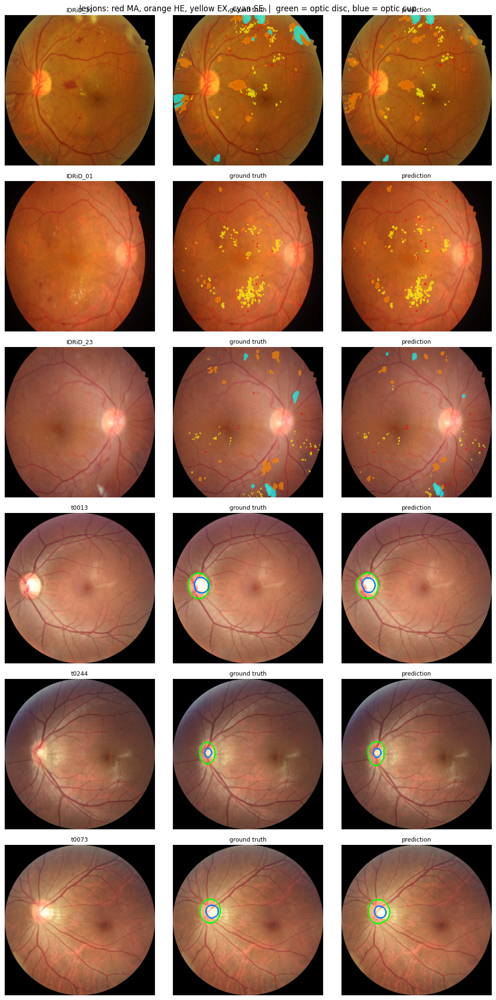

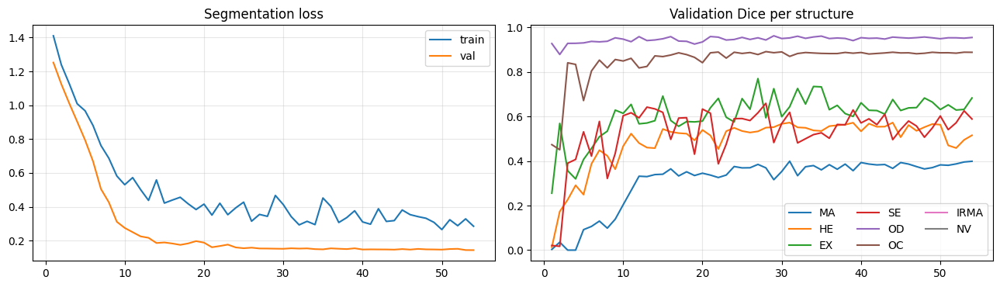

In [42]:
# ============ CELL 14 : SEGMENTATION TESTING (Dice, IoU, precision, recall, vertical CDR) + visual check ============
seg_model.load_state_dict(torch.load(SEG_BEST, map_location=DEVICE)); seg_model.eval()

@torch.no_grad()
def seg_predict(loader):
    P, Y, A = [], [], []
    for x, y, a in loader:
        with torch.autocast(DEVICE_TYPE, dtype=torch.float16, enabled=USE_CUDA): lg = seg_model(x.to(DEVICE).contiguous(memory_format=torch.channels_last))
        P.append(torch.sigmoid(lg.float()).half().cpu()); Y.append(y.byte()); A.append(a)
    return torch.cat(P).numpy(), torch.cat(Y).numpy(), torch.cat(A).numpy()

def stats(p, y):
    tp, fp, fn = int((p & y).sum()), int((p & ~y).sum()), int((~p & y).sum())
    return dict(dice=2 * tp / max(2 * tp + fp + fn, 1), iou=tp / max(tp + fp + fn, 1), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1))

# ---- per-structure threshold tuned on the VALIDATION set (not on test) ----
Pv, Yv, Av = seg_predict(seg_val_loader); SEG_THR = {}
for k, c in enumerate(SEG_CH):
    sel = Av[:, k] > 0
    if not sel.any(): SEG_THR[c] = 0.5; continue
    grid = np.arange(0.1, 0.91, 0.05); sc = [stats(Pv[sel, k] >= t, Yv[sel, k] > 0)['dice'] for t in grid]; SEG_THR[c] = float(round(grid[int(np.argmax(sc))], 2))
json.dump(SEG_THR, open(OUT_DIR / 'seg_thresholds.json', 'w')); print('tuned thresholds (val):', SEG_THR)

Pt, Yt, At = seg_predict(seg_test_loader); srcs = np.array([i['src'] for i in SEG['test']]); rows = []
for src in sorted(set(srcs)):
    for k, c in enumerate(SEG_CH):
        sel = (srcs == src) & (At[:, k] > 0)
        if sel.any(): rows.append(dict(source=src, structure=c, n_images=int(sel.sum()), **stats(Pt[sel, k] >= SEG_THR[c], Yt[sel, k] > 0)))
seg_res = pd.DataFrame(rows).round(4); seg_res.to_csv(OUT_DIR / 'seg_test_metrics.csv', index=False); print(seg_res.to_string(index=False))

# ---- vertical cup-to-disc ratio (glaucoma evidence) ----
def largest_cc(mask):
    n, lab, st, _ = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    return (lab == 1 + int(np.argmax(st[1:, cv2.CC_STAT_AREA]))) if n > 1 else np.zeros_like(mask, bool)
def vcdr(disc, cup):
    rd, rc = np.where(disc.any(1))[0], np.where(cup.any(1))[0]
    return float((rc.max() - rc.min() + 1) / (rd.max() - rd.min() + 1)) if len(rd) and len(rc) else float('nan')

ref = [i for i in range(len(srcs)) if srcs[i] == 'refuge' and At[i, 4] > 0 and At[i, 5] > 0]
if ref:
    g_cdr, p_cdr = [], []
    for i in ref:
        d = largest_cc(Pt[i, 4] >= SEG_THR['OD']); c = (Pt[i, 5] >= SEG_THR['OC']) & d
        g_cdr.append(vcdr(Yt[i, 4] > 0, Yt[i, 5] > 0)); p_cdr.append(vcdr(d, c))
    g_cdr, p_cdr = np.array(g_cdr), np.array(p_cdr); ok = np.isfinite(g_cdr) & np.isfinite(p_cdr)
    print(f'\nvertical CDR on REFUGE test ({ok.sum()} images): MAE {np.abs(g_cdr[ok] - p_cdr[ok]).mean():.4f} | correlation {np.corrcoef(g_cdr[ok], p_cdr[ok])[0, 1]:.3f}')
    glc = np.array([SEG['test'][i]['name'].lower().startswith('g') for i in ref])
    if ok.sum() and 0 < glc[ok].sum() < ok.sum(): print(f'glaucoma AUC using the predicted vertical CDR alone: {roc_auc_score(glc[ok], p_cdr[ok]):.3f}')

# ---- visual check: image | ground truth | prediction ----
LES_RGB = {'MA': (255, 0, 0), 'HE': (255, 140, 0), 'EX': (255, 255, 0), 'SE': (0, 255, 255)}
def overlay_lesions(img, M):
    out = img.astype(np.float32).copy()
    for k, c in enumerate(['MA', 'HE', 'EX', 'SE']):
        m = cv2.dilate(M[k].astype(np.uint8), np.ones((3, 3), np.uint8)) > 0; out[m] = 0.35 * out[m] + 0.65 * np.array(LES_RGB[c], np.float32)
    return out.astype(np.uint8)
def overlay_dc(img, disc, cup):
    out = img.copy()
    for m, col in ((disc, (0, 255, 0)), (cup, (0, 120, 255))):
        cs, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(out, cs, -1, col, 3)
    return out
show = [i for s_ in ('idrid', 'fgadr', 'ddr', 'refuge') for i in [j for j in range(len(srcs)) if srcs[j] == s_][:3]]
fig, ax = plt.subplots(len(show), 3, figsize=(11, 3.6 * len(show)), squeeze=False)
for r, i in enumerate(show):
    img = SEG['test'][i]['img']; ax[r, 0].imshow(img); ax[r, 0].set_title(SEG['test'][i]['name'], fontsize=9)
    if srcs[i] in ('idrid', 'fgadr', 'ddr'):
        ax[r, 1].imshow(overlay_lesions(img, Yt[i] > 0)); ax[r, 2].imshow(overlay_lesions(img, [Pt[i, k] >= SEG_THR[c] for k, c in enumerate(SEG_CH[:4])]))
    else:
        ax[r, 1].imshow(overlay_dc(img, Yt[i, 4] > 0, Yt[i, 5] > 0)); ax[r, 2].imshow(overlay_dc(img, largest_cc(Pt[i, 4] >= SEG_THR['OD']), (Pt[i, 5] >= SEG_THR['OC'])))
    ax[r, 1].set_title('ground truth', fontsize=9); ax[r, 2].set_title('prediction', fontsize=9)
    for a_ in ax[r]: a_.axis('off')
plt.suptitle('lesions: red MA, orange HE, yellow EX, cyan SE  |  green = optic disc, blue = optic cup'); plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'seg_test_samples.png', dpi=110); plt.show()

sl = pd.read_csv(SEG_LOG); fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(sl.epoch, sl.train_loss, label='train'); ax[0].plot(sl.epoch, sl.val_loss, label='val'); ax[0].set_title('Segmentation loss'); ax[0].legend(); ax[0].grid(alpha=.3)
for c in SEG_CH: ax[1].plot(sl.epoch, sl[f'dice_{c}'], label=c)
ax[1].set_title('Validation Dice per structure'); ax[1].legend(ncol=3); ax[1].grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT_DIR / 'figs' / 'seg_curves.png', dpi=130); plt.show()

13 images -> ['3441_left.jpg', '4136_right.jpg', '1212_left.jpg', '24_right.jpg', '775_left.jpg', '4129_left.jpg', '1526_right.jpg', '632_left.jpg', '7b9d519cbd66.png', 'a5a2a7003d60.png', '1c5e6cdc7ee1.png', '8a234d68b27e.png', 'd48178e4a49b.png']


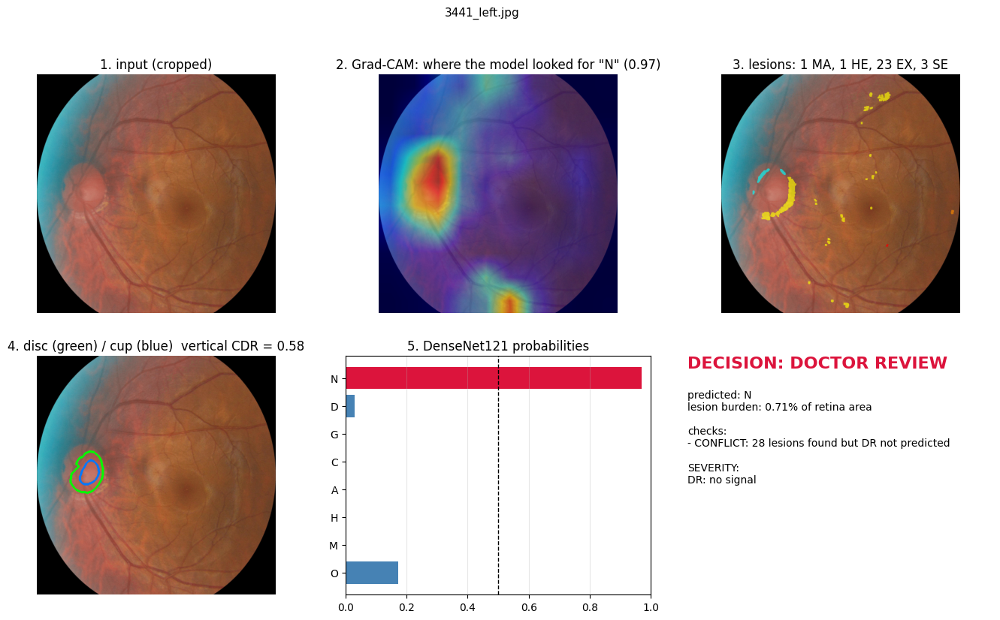

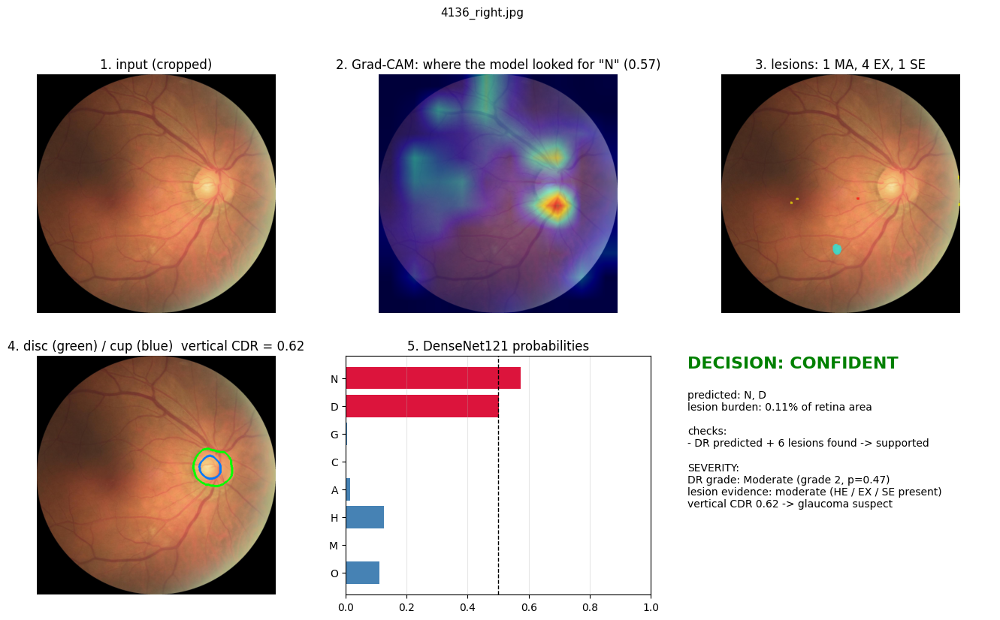

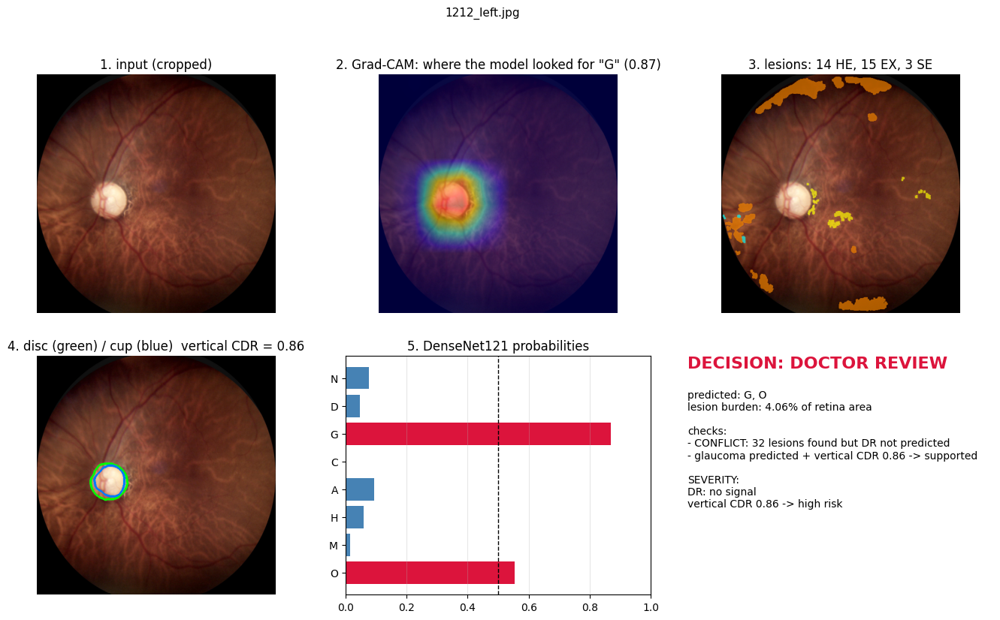

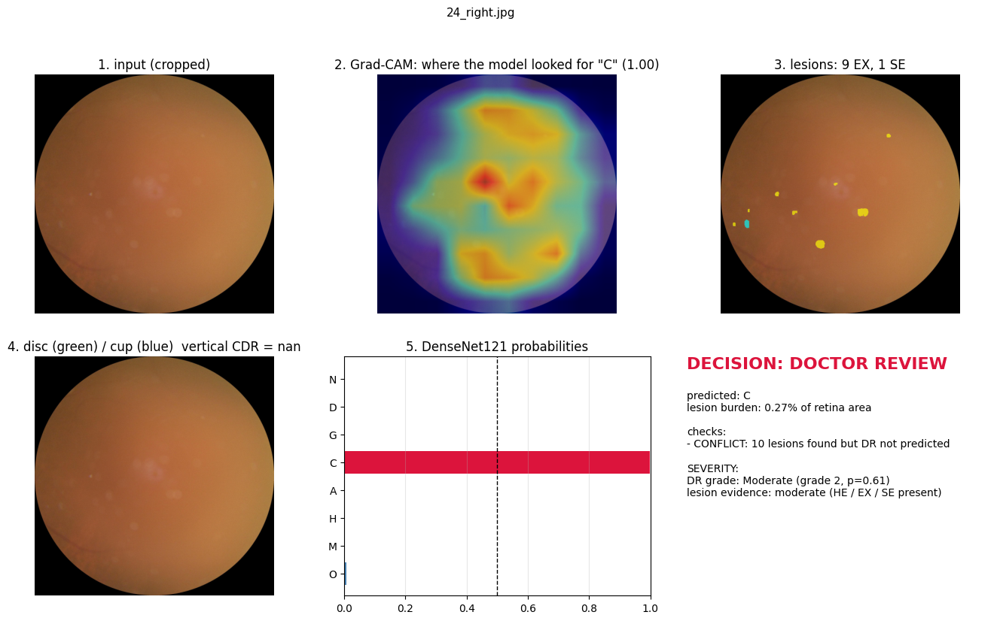

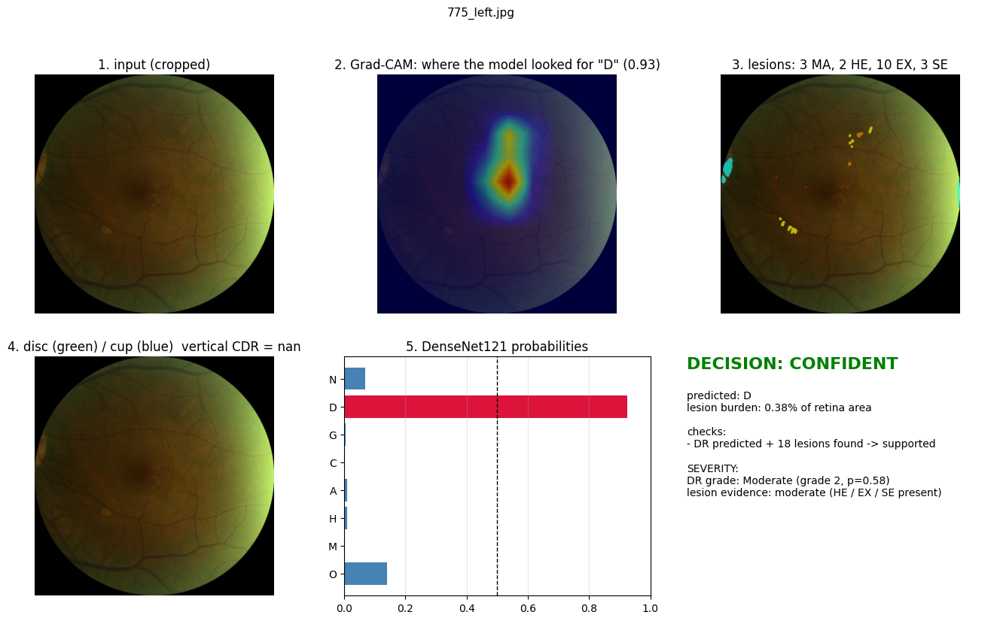

...

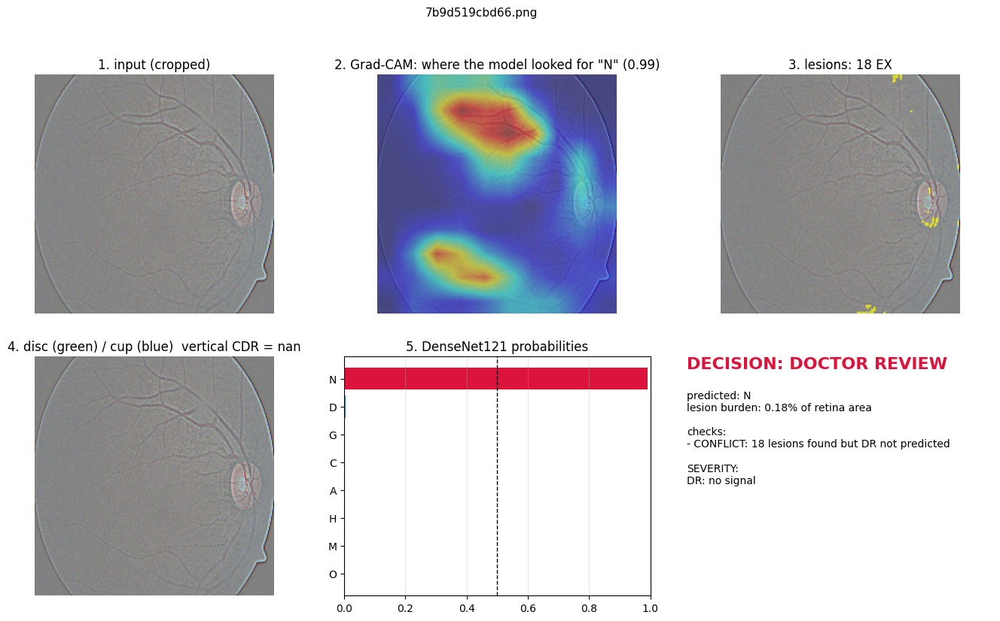

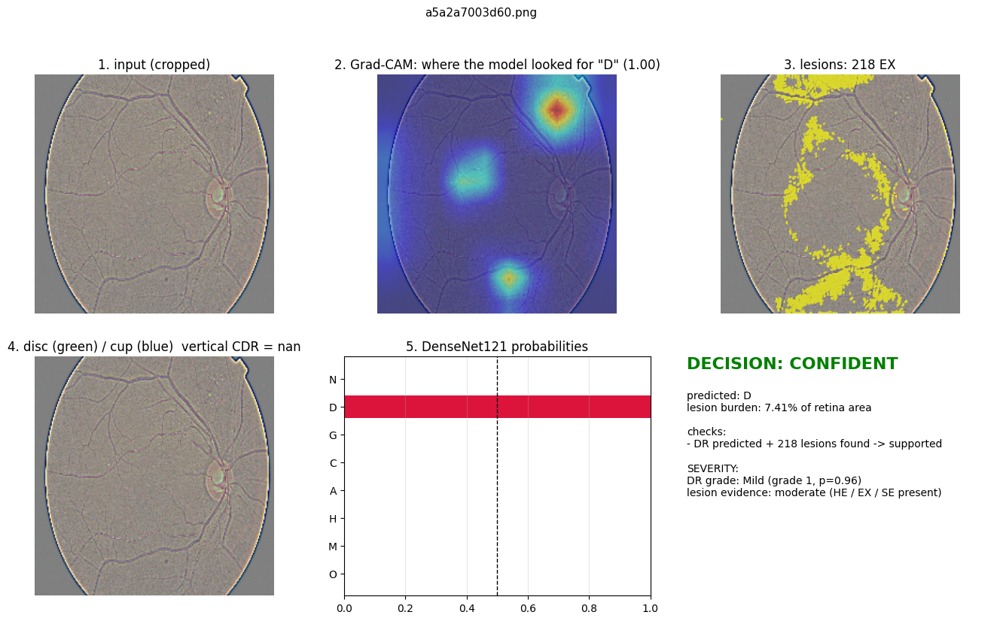

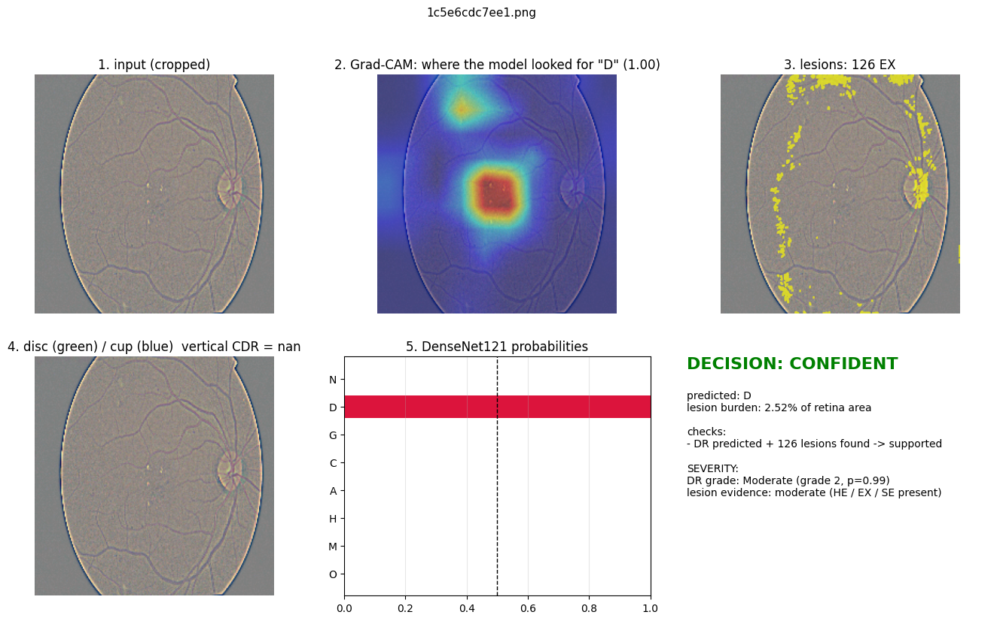

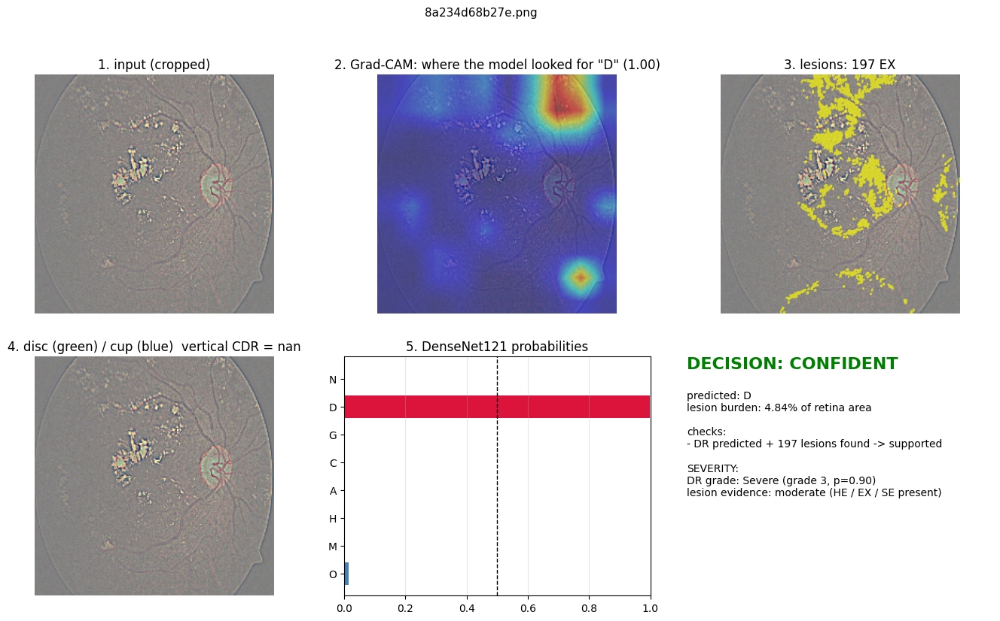

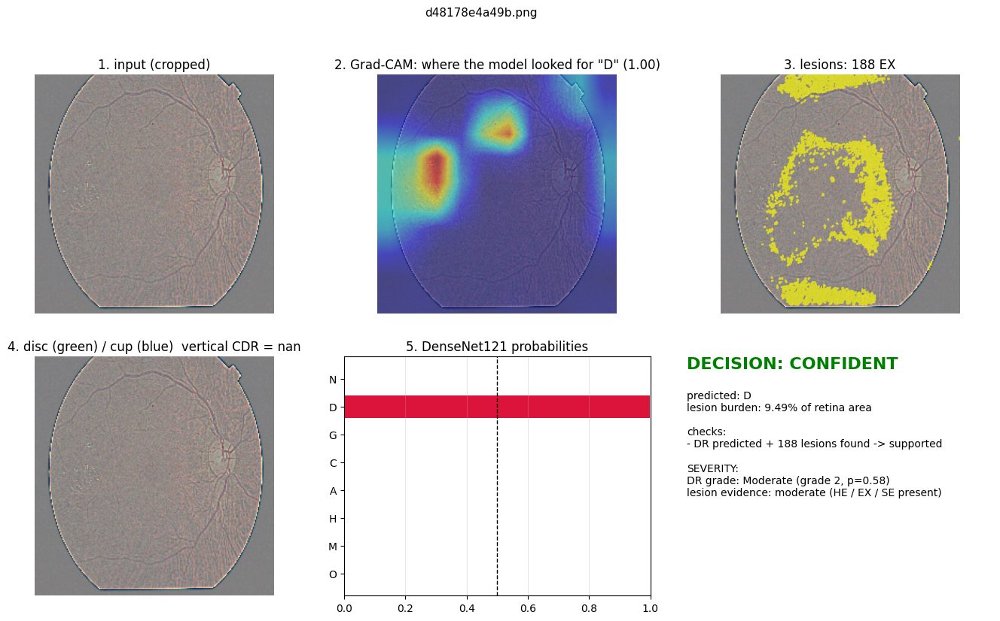

           image predicted  vertical_cdr      decision                                                      severity
   3441_left.jpg       [N]         0.578 DOCTOR REVIEW                                                       DR none
  4136_right.jpg    [N, D]         0.617     CONFIDENT DR Moderate (grade 2) | vertical CDR 0.62 -> glaucoma suspect
   1212_left.jpg    [G, O]         0.859 DOCTOR REVIEW                      DR none | vertical CDR 0.86 -> high risk
    24_right.jpg       [C]           NaN DOCTOR REVIEW                                         DR Moderate (grade 2)
    775_left.jpg       [D]           NaN     CONFIDENT                                         DR Moderate (grade 2)
   4129_left.jpg    [N, H]         0.559     CONFIDENT                                                       DR none
  1526_right.jpg    [M, O]         0.434 DOCTOR REVIEW                                    DR Proliferative (grade 4)
    632_left.jpg        []         0.780 DOCTOR REVIEW          

/kaggle/working/fundus_ai_results.zip

In [43]:
# ============ CELL 15 : FULL PIPELINE -> Grad-CAM + classification + lesions + disc/cup (CDR) + consistency check + final ZIP ============
CUSTOM_IMAGE_DIR = None        # e.g. '/content/my_images'  (upload fundus images to Colab and put the folder here). None = use ODIR test images
MIN_AREA = {'MA': 2, 'HE': 8, 'EX': 5, 'SE': 12}          # smallest blob (pixels @512) counted as a lesion
core(model).load_state_dict(torch.load(BEST_PT, map_location=DEVICE)); model.eval(); seg_model.eval()
grade_model.load_state_dict(torch.load(GR_BEST, map_location=DEVICE)); grade_model.eval()
seg_model.load_state_dict(torch.load(SEG_BEST, map_location=DEVICE)); seg_model.eval()

class GradCAM:
    def __init__(self, net): self.net, self.act = net, None; net.features.register_forward_hook(lambda m, i, o: setattr(self, 'act', o))
    def __call__(self, x, k, size):
        self.net.eval(); self.net.zero_grad(set_to_none=True)
        with torch.enable_grad():
            logit = self.net(x)[0, k]; g = torch.autograd.grad(logit, self.act)[0]
        cam = F.relu((g.mean((2, 3), keepdim=True) * self.act.detach()).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(size, size), mode='bilinear', align_corners=False)[0, 0].cpu().numpy(); cam -= cam.min()
        return cam / (cam.max() + 1e-8)
cam_engine = GradCAM(core(model))

def classify(pil):
    x = TF['test'](pil)[None].to(DEVICE)
    with torch.no_grad(): lg = (core(model)(x) + core(model)(torch.flip(x, dims=[3]))) / 2        # flip test-time augmentation
    return torch.sigmoid(lg.float())[0].cpu().numpy(), x

def segment(img_rgb):
    im, _ = prep_seg_image(img_rgb); x = torch.from_numpy(((im.astype(np.float32) / 255 - SEG_MEAN) / SEG_STD).transpose(2, 0, 1).copy())[None].to(DEVICE)
    with torch.no_grad(), torch.autocast(DEVICE_TYPE, dtype=torch.float16, enabled=USE_CUDA): p = torch.sigmoid(seg_model(x.contiguous(memory_format=torch.channels_last)).float())[0].cpu().numpy()
    return im, p

def lesion_summary(p):
    masks, counts, area = [], {}, 0
    for k, c in enumerate(SEG_CH[:4]):
        m = (p[k] >= SEG_THR[c]).astype(np.uint8); n, lab, st, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
        keep = np.isin(lab, [j for j in range(1, n) if st[j, cv2.CC_STAT_AREA] >= MIN_AREA[c]]); masks.append(keep); counts[c] = int(sum(st[j, cv2.CC_STAT_AREA] >= MIN_AREA[c] for j in range(1, n))); area += int(keep.sum())
    return masks, counts, area / float(SEG_SIZE * SEG_SIZE)

def consistency(P, counts, cdr):
    """simple transparent rules: does the pixel-level evidence agree with the classifier?"""
    notes, conflict, n_les = [], False, sum(counts.values())
    if P['D'] >= THRESHOLD:
        if n_les > 0: notes.append(f'DR predicted + {n_les} lesions found -> supported')
        else: notes.append('CONFLICT: DR predicted but no lesion segmented'); conflict = True
    elif n_les >= 5: notes.append(f'CONFLICT: {n_les} lesions found but DR not predicted'); conflict = True
    if np.isfinite(cdr):
        if P['G'] >= THRESHOLD:
            if cdr >= 0.6: notes.append(f'glaucoma predicted + vertical CDR {cdr:.2f} -> supported')
            elif cdr < 0.5: notes.append(f'CONFLICT: glaucoma predicted but vertical CDR only {cdr:.2f}'); conflict = True
            else: notes.append(f'glaucoma predicted, CDR {cdr:.2f} borderline')
        elif cdr >= 0.7: notes.append(f'CONFLICT: vertical CDR {cdr:.2f} is high but glaucoma not predicted'); conflict = True
    if not notes: notes.append('no disease evidence to cross-check')
    return ('DOCTOR REVIEW' if conflict else 'CONFIDENT'), notes

# ---------------- SEVERITY ENGINE : DR grade (grade model) + lesion evidence (segmentation) + glaucoma stage (CDR) ----------------
ACTIVE = {c for k, c in enumerate(SEG_CH) if any(i['avail'][k] > 0 for i in SEG['train'])}      # channels that really had masks in training
LES_STAGE = ['no lesion found', 'mild (MA only)', 'moderate (HE / EX / SE present)', 'severe (HE in all 4 quadrants or IRMA)', 'proliferative (new vessels)']

def predict_grade(pil):
    x = grade_prep(pil)[None].to(DEVICE)
    with torch.no_grad(): lg = (grade_model(x) + grade_model(torch.flip(x, dims=[3]))) / 2        # flip test-time augmentation
    return torch.softmax(lg.float(), 1)[0].cpu().numpy()

def _blobs(m, min_area):
    n, _, st, _ = cv2.connectedComponentsWithStats(m.astype(np.uint8), connectivity=8)
    return int(sum(st[j, cv2.CC_STAT_AREA] >= min_area for j in range(1, n)))

def lesion_stage(p):
    """HEURISTIC DR stage from the segmented lesions (ICDR-inspired). Used only as a cross-check of the grade model, not as a diagnosis."""
    z = np.zeros((SEG_SIZE, SEG_SIZE), bool)
    m = {c: ((p[SEG_CH.index(c)] >= SEG_THR[c]) if c in ACTIVE else z) for c in ('MA', 'HE', 'EX', 'SE', 'IRMA', 'NV')}
    h = SEG_SIZE // 2; quads = [(slice(0, h), slice(0, h)), (slice(0, h), slice(h, None)), (slice(h, None), slice(0, h)), (slice(h, None), slice(h, None))]
    he_q = [_blobs(m['HE'][q], MIN_AREA['HE']) for q in quads]
    irma_q = sum(int(m['IRMA'][q].sum() >= 40) for q in quads)
    n_ma, n_ex, n_se = _blobs(m['MA'], MIN_AREA['MA']), _blobs(m['EX'], MIN_AREA['EX']), _blobs(m['SE'], MIN_AREA['SE'])
    if int(m['NV'].sum()) >= 60: s = 4
    elif min(he_q) >= 20 or irma_q >= 2: s = 3
    elif sum(he_q) + n_ex + n_se > 0: s = 2
    elif n_ma > 0: s = 1
    else: s = 0
    return dict(stage=s, name=LES_STAGE[s], he_quadrants=he_q)

def glaucoma_stage(cdr):
    if not np.isfinite(cdr): return 'vertical CDR not measurable'
    return f'vertical CDR {cdr:.2f} -> ' + ('normal range' if cdr < 0.5 else 'borderline' if cdr < 0.6 else 'glaucoma suspect' if cdr < 0.7 else 'high risk')

def severity_report(pil, P, cdr, p):
    gp = predict_grade(pil); g = int(gp.argmax()); ls = lesion_stage(p); lines, parts, conflict = [], [], False
    if g >= 1 or P['D'] >= THRESHOLD:
        lines += [f'DR grade: {GRADE_NAMES[g]} (grade {g}, p={gp[g]:.2f})', f'lesion evidence: {ls["name"]}']
        parts.append(f'DR {GRADE_NAMES[g]} (grade {g})')
        if abs(g - ls['stage']) >= 2: conflict = True; lines.append('CONFLICT: grade model and lesions disagree by 2+ grades')
    else: lines.append('DR: no signal'); parts.append('DR none')
    if P['G'] >= THRESHOLD or (np.isfinite(cdr) and cdr >= 0.6): lines.append(glaucoma_stage(cdr)); parts.append(glaucoma_stage(cdr))
    return dict(lines=lines, summary=' | '.join(parts), conflict=conflict, grade=g, grade_probs=gp)

def make_report(path, save=None):
    img = read_rgb(path); pil = Image.fromarray(img)
    probs, x = classify(pil); P = dict(zip(CLASSES, probs)); k = int(np.argmax(probs))
    im, p = segment(img); les_masks, counts, burden = lesion_summary(p)
    disc = largest_cc(p[4] >= SEG_THR['OD']); cup = (p[5] >= SEG_THR['OC']) & disc; cdr = vcdr(disc, cup) if disc.any() and cup.any() else float('nan')
    decision, notes = consistency(P, counts, cdr)
    sev = severity_report(pil, P, cdr, p)
    if sev['conflict']: decision = 'DOCTOR REVIEW'; notes.append('CONFLICT: DR grade model vs lesion evidence')
    cam = cam_engine(x, k, SEG_SIZE); heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[:, :, ::-1]
    fig = plt.figure(figsize=(17, 9)); gs = fig.add_gridspec(2, 3, hspace=0.18, wspace=0.12)
    ax = fig.add_subplot(gs[0, 0]); ax.imshow(im); ax.set_title('1. input (cropped)'); ax.axis('off')
    ax = fig.add_subplot(gs[0, 1]); ax.imshow(cv2.addWeighted(im, 0.55, heat, 0.45, 0)); ax.set_title(f'2. Grad-CAM: where the model looked for "{CLASSES[k]}" ({probs[k]:.2f})'); ax.axis('off')
    ax = fig.add_subplot(gs[0, 2]); ax.imshow(overlay_lesions(im, les_masks)); ax.set_title('3. lesions: ' + (', '.join(f'{v} {c}' for c, v in counts.items() if v) or 'none')); ax.axis('off')
    ax = fig.add_subplot(gs[1, 0]); ax.imshow(overlay_dc(im, disc, cup)); ax.set_title(f'4. disc (green) / cup (blue)  vertical CDR = {cdr:.2f}'); ax.axis('off')
    ax = fig.add_subplot(gs[1, 1]); ax.barh(CLASSES[::-1], probs[::-1], color=['crimson' if v >= THRESHOLD else 'steelblue' for v in probs[::-1]]); ax.axvline(THRESHOLD, c='k', ls='--', lw=1)
    ax.set_xlim(0, 1); ax.set_title('5. DenseNet121 probabilities'); ax.grid(alpha=.3, axis='x')
    ax = fig.add_subplot(gs[1, 2]); ax.axis('off'); col = 'green' if decision == 'CONFIDENT' else 'crimson'
    ax.text(0, 1, f'DECISION: {decision}', fontsize=16, weight='bold', color=col, va='top')
    ax.text(0, 0.86, 'predicted: ' + (', '.join(c for c in CLASSES if P[c] >= THRESHOLD) or 'none above threshold') + f'\nlesion burden: {100 * burden:.2f}% of retina area\n\nchecks:\n' + '\n'.join('- ' + n for n in notes) + '\n\nSEVERITY:\n' + '\n'.join(sev['lines']), fontsize=10, va='top', wrap=True)
    plt.suptitle(Path(path).name, fontsize=11)
    if save: plt.savefig(save, dpi=110, bbox_inches='tight')
    plt.show()
    return dict(image=Path(path).name, probs={c: round(float(P[c]), 4) for c in CLASSES}, predicted=[c for c in CLASSES if P[c] >= THRESHOLD], lesion_counts=counts,
                lesion_burden=round(burden, 5), vertical_cdr=None if not np.isfinite(cdr) else round(cdr, 3), decision=decision, checks=notes, severity=sev['summary'])

if CUSTOM_IMAGE_DIR: paths = sorted(p for p in Path(CUSTOM_IMAGE_DIR).rglob('*') if p.suffix.lower() in IMG_EXT)
else:
    t = te_df[te_df.source == 'odir']; paths = [Path(t[t[c] == 1].sample(1, random_state=SEED).iloc[0].path) for c in CLASSES if (t[c] == 1).any()]
if not CUSTOM_IMAGE_DIR:                                     # also one test image per DR grade (aptos / idrid / fgadr)
    gt = te_df[te_df.grade >= 0]; paths += [Path(gt[gt.grade == g_].sample(1, random_state=SEED).iloc[0].path) for g_ in range(5) if (gt.grade == g_).any()]
print(len(paths), 'images ->', [p.name for p in paths])
reports = []
for p in paths:
    reports.append(make_report(p, OUT_DIR / 'reports' / f'{p.stem}_report.png'))
json.dump(reports, open(OUT_DIR / 'reports' / 'all_reports.json', 'w'), indent=2)
print(pd.DataFrame([{k: v for k, v in r.items() if k in ('image', 'predicted', 'vertical_cdr', 'decision', 'severity')} for r in reports]).to_string(index=False))

zip_path = shutil.make_archive(str(ROOT / 'fundus_ai_results'), 'zip', OUT_DIR)          # models + csv + figures + reports
print('\nALL results zipped ->', zip_path); download_file(zip_path)

In [44]:
# ================================================================
# MANUAL UPLOAD → COMPLETE FUNDUS AI PIPELINE
# ================================================================

from IPython.display import display
import ipywidgets as widgets
from pathlib import Path
from PIL import Image

# ------------------------------------------------
# 1. UPLOAD IMAGE
# ------------------------------------------------
upload = widgets.FileUpload(
    accept='.jpg,.jpeg,.png',
    multiple=False,
    description='Upload Fundus Image'
)

display(upload)

FileUpload(value=(), accept='.jpg,.jpeg,.png', description='Upload Fundus Image')

UPLOADED IMAGE
adb56cecafaf.png


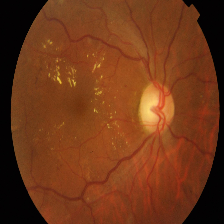


⏳ Running ALL trained models...


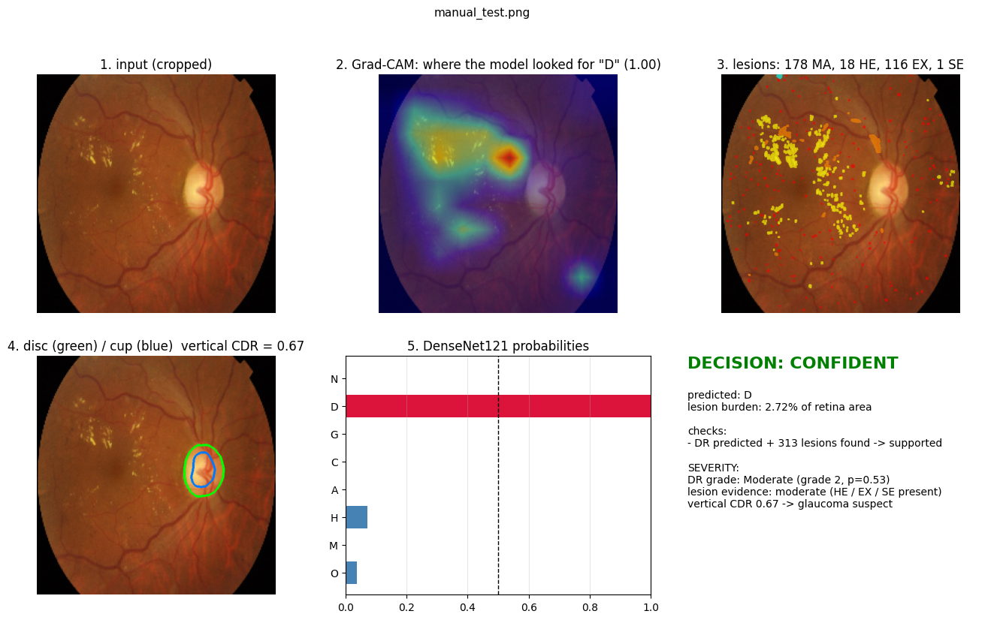


                    COMPLETE RESULT

🩺 DISEASE CLASSIFICATION
['D']

🩸 DR SEVERITY
DR Moderate (grade 2) | vertical CDR 0.67 -> glaucoma suspect

👁️ VERTICAL CDR
0.67

🔬 LESION COUNTS
MA: 178
HE: 18
EX: 116
SE: 1

⚠️ CONSISTENCY CHECKS
 - DR predicted + 313 lesions found -> supported

🚦 FINAL DECISION
CONFIDENT

                    FULL REPORT


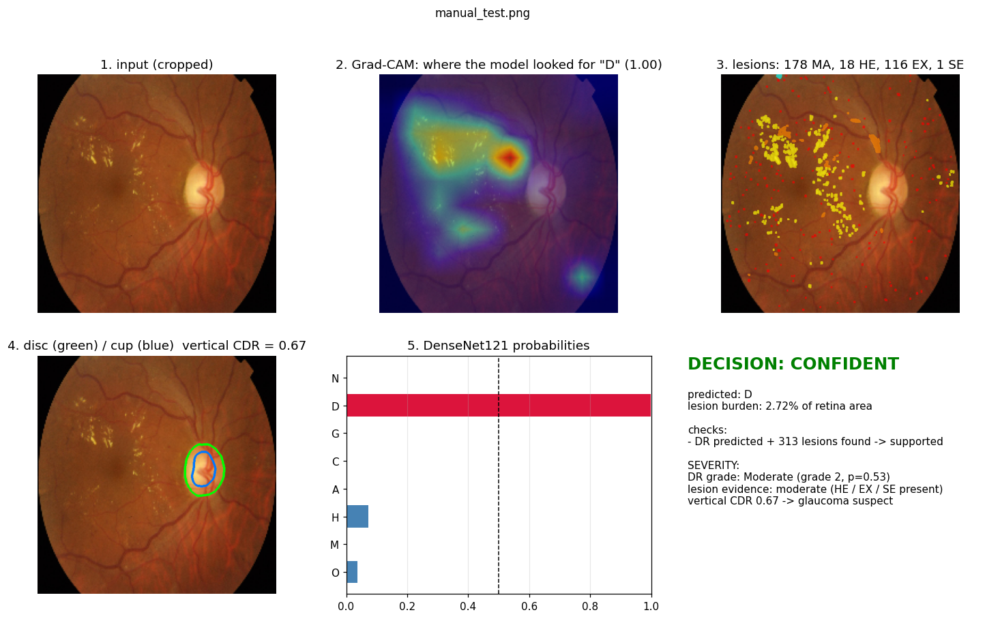


✅ DONE


In [45]:
# ================================================================
# RUN UPLOADED IMAGE THROUGH THE COMPLETE TRAINED PIPELINE
# ================================================================

if len(upload.value) == 0:
    print("❌ Please upload an image first.")

else:

    # Kaggle / ipywidgets newer format = tuple
    file = upload.value[0]

    image_name = file["name"]
    image_bytes = file["content"]

    # Save image
    ext = Path(image_name).suffix.lower()
    img_path = Path("/kaggle/working/manual_test" + ext)

    with open(img_path, "wb") as f:
        f.write(image_bytes)

    print("=" * 70)
    print("UPLOADED IMAGE")
    print("=" * 70)
    print(image_name)

    display(Image.open(img_path).convert("RGB"))

    # ------------------------------------------------------------
    # THIS IS THE IMPORTANT PART
    # ------------------------------------------------------------
    # make_report() from your Cell 15 sends the image through
    # your ALREADY TRAINED models.
    #
    # No training happens here.
    # ------------------------------------------------------------

    print("\n⏳ Running ALL trained models...")
    
    report_path = OUT_DIR / "reports" / "manual_test_report.png"

    result = make_report(
        img_path,
        report_path
    )

    # ------------------------------------------------------------
    # RESULTS
    # ------------------------------------------------------------

    print("\n" + "=" * 70)
    print("                    COMPLETE RESULT")
    print("=" * 70)

    print("\n🩺 DISEASE CLASSIFICATION")
    print(result["predicted"])

    print("\n🩸 DR SEVERITY")
    print(result["severity"])

    print("\n👁️ VERTICAL CDR")
    print(result["vertical_cdr"])

    print("\n🔬 LESION COUNTS")
    for k, v in result["lesion_counts"].items():
        print(f"{k}: {v}")

    print("\n⚠️ CONSISTENCY CHECKS")
    for x in result["checks"]:
        print(" -", x)

    print("\n🚦 FINAL DECISION")
    print(result["decision"])

    # ------------------------------------------------------------
    # FULL 6-PANEL REPORT
    # ------------------------------------------------------------

    print("\n" + "=" * 70)
    print("                    FULL REPORT")
    print("=" * 70)

    display(Image.open(report_path))

    print("\n✅ DONE")